# "The Entrainment of Air from Rainy Surface Regions and its Implications for Bioaerosol Transport in Three Deep Convective Storm Morphologies" (Davis et al.) analysis notebook

This notebook produces all of the analysis and figures presented in the manuscript named above. Assuming the required RAMS output is present, it should work out of the box (or nearly so),
with only a few possible changes you could need to make, described here:

* The `common` and `blt_utils` packages used throughout are included, and should be found automatically by python. If they are not,
  you can ensure that the appropriate directories/locations are included using `sys.path.append`.
* Assuming you have reproduced the RAMS output, you will need to modify the `RAMS_OUTPUT_DIRS` variable in `blt_utils.py` to point to the
  directories containing the RAMS output for each storm. All other paths are relative and should not need to be adjusted.
* If `USE_DASK_LOCAL_CLUSTER` is set to True, xarray will try to read in the RAMS data using the dask backend. This is set to False
  by default so that the code will work, but if you wish to use dask, start your own scheduler and modify the `DASK_SCHEDULER_ADDRESS`
  variable in `blt_utils.py`
* In the "Read/calculate data"/"Tracer concentration files" and "Read/calculate data"/"Development dataframes" cells below,
  the flags for each storm in the top of the cell can be set to False to recalculate the derived dataset from the raw
  RAMS output. With the default True, these will be read from disk (they are included with the repo).

# Setup

## Imports

In [1]:
# Native packages
from pathlib import Path
from importlib import reload
import re

# Other packages
import pandas as pd
import xarray as xr
import pint_xarray
import numpy as np
from metpy.plots import SkewT, Hodograph
import metpy.calc as mpc
from metpy.units import units
import metpy.constants as mpconstants
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.pyplot as plt
import matplotlib.animation as mplanim
from matplotlib.animation import FuncAnimation
from matplotlib import ticker
import matplotlib.colors as colors
import matplotlib as mpl
import matplotlib.patches as patches
from IPython.display import HTML, display, Image
from tqdm.notebook import tqdm
import pickle as pkl
from scipy import interpolate
from sklearn.linear_model import LinearRegression

# My packages
import common_limited as cm
import blt_utils_limited as blt

plt.style.use(blt.MPL_STYLE)

# Make a default function for saving figures and data to the right place
# and with the right extensions
save_figure_and_data = lambda: cm.plotting.save_figure_and_data(
    figure_output_dirs=[blt.FIGS_DIR],
    data_output_dirs=[blt.FIGURE_DATA_DIR],
    extensions=[".pdf", ".png"],
)

## Parameters

In [2]:
# Explicitly parallelizing over the local machine is similaraly finnicky, so add a flag for it
USE_DASK_LOCAL_CLUSTER = True

display(blt.RAMS_OUTPUT_DIRS)
display(blt.DEVELOPMENT_DATAFRAME_FILEPATHS)
display(blt.TRACER_TOTALS_PROFILE_FILEPATHS)

{'ic_wk': PosixPath('/moonbow/cmdavis4/projects/bl_transport/rams_io/isolated_convection_wk/all_tracers/newtracer_forcing-warmbubble4_deltax-500_frqlite-2_nobulku/output'),
 'sl_wk': PosixPath('/moonbow/cmdavis4/projects/bl_transport/rams_io/squall_line_wk/all_tracers/newtracer_blspinup-no_forcing-infinitecoldbubble4_deltax-500_frqlite-2/output'),
 'sc_wk': PosixPath('/moonbow/cmdavis4/projects/bl_transport/rams_io/supercell_wk/all_tracers/newtracer_forcing-grant2014_dx-500_frqlite-2_stratwinds/output')}

{'ic_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/development_dataframe.pkl'),
 'sl_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/development_dataframe.pkl'),
 'sc_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/development_dataframe.pkl')}

{'ic_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/tracer_totals_profile_ds.nc'),
 'sl_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/tracer_totals_profile_ds.nc'),
 'sc_wk': PosixPath('/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/tracer_totals_profile_ds.nc')}

## Dask cluster

In [3]:
if USE_DASK_LOCAL_CLUSTER:
    from dask.distributed import Client, LocalCluster

    # cluster = LocalCluster()
    # client = Client(cluster)
    client = Client("127.0.0.1:8786")

# Read/calculate data

## 5 minute RAMS output

In [4]:
reload(cm.rams)
reload(blt)

# Define the list of RAMS output filenames we'll read in
# Can specify this manually or just use a glob
rams_input_filename_glob = "a-A-*.h5"

rams_input_dim_names_kwargs = (
    {
        "dim_names": {
            "phony_dim_0": "y",
            "phony_dim_1": "x",
            "phony_dim_2": "p",
            "phony_dim_3": "z",
        }
    }
    if rams_input_filename_glob.startswith("a-L")
    else {}
)

storm_dss = {}

for storm_name in tqdm(list(blt.STORM_LABELS.keys())):
    rams_input_filenames = sorted(
        list(blt.RAMS_OUTPUT_DIRS[storm_name].glob(rams_input_filename_glob))
    )

    # Read in the RAMS output
    storm_ds = cm.rams.read_rams_output(
        input_filenames=rams_input_filenames,
        time_dim_name="time",
        units=False,
        **rams_input_dim_names_kwargs,
    )

    # Postprocess
    storm_ds = blt.postprocess_storm_ds(storm_ds, storm_name)

    # Store
    storm_dss[storm_name] = storm_ds


# Calculate the timestep and horizontal grid spacing, assuming they are uniform
# Doesn't matter which storm ds we use
DELTA_T = (storm_ds["time"].values[1] - storm_ds["time"].values[0]) / np.timedelta64(
    1, "s"
)
DELTA_X = storm_ds["x"].values[1] - storm_ds["x"].values[0]

  0%|          | 0/3 [00:00<?, ?it/s]

Reading and concatenating 37 RAMS individual timestep outputs...
Reading and concatenating 37 RAMS individual timestep outputs...
Reading and concatenating 37 RAMS individual timestep outputs...


## Tracer concentration files

In [5]:
reload(blt)

# Whether to read this from disk; if not, it recalculates it and save it to disk
READ_TRACER_CONCENTRATIONS = {"ic_wk": True, "sl_wk": True, "sc_wk": True}

tracer_totals_profile_dss = {}
for storm, storm_ds in storm_dss.items():

    tracer_totals_profile_filepath = blt.TRACER_TOTALS_PROFILE_FILEPATHS[storm]
    print(tracer_totals_profile_filepath)
    # continue
    if READ_TRACER_CONCENTRATIONS[storm]:
        tracer_totals_profile_ds = xr.open_dataset(tracer_totals_profile_filepath)
    else:
        tracer_totals_profile_ds = blt.calculate_tracer_profile_ds(
            storm_ds.where(storm_ds["in_analysis"])
        )
        # Save it to disk
        print("Saving...")
        tracer_totals_profile_ds.to_netcdf(tracer_totals_profile_filepath)
    # Store it
    tracer_totals_profile_dss[storm] = tracer_totals_profile_ds

# Calculate totals across vertical levels
tracer_totals_dss = {
    k: v.isel({"z": slice(1, len(v["z"]))}).sum("z")
    for k, v in tracer_totals_profile_dss.items()
}

/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/tracer_totals_profile_ds.nc
/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/tracer_totals_profile_ds.nc
/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/tracer_totals_profile_ds.nc


## Development dataframes

In [6]:
reload(blt)

READ_DEVELOPMENT_DATAFRAMES = {"ic_wk": True, "sl_wk": True, "sc_wk": True}

development_dfs = {}

for storm, storm_ds in tqdm(storm_dss.items()):

    development_df_filepath = blt.DEVELOPMENT_DATAFRAME_FILEPATHS[storm]
    print(development_df_filepath)

    if READ_DEVELOPMENT_DATAFRAMES[storm]:
        development_df = pd.read_pickle(development_df_filepath)
    else:
        development_df = blt.calculate_development_dataframe(
            storm_ds.where(storm_ds["in_analysis"])
        )
        # Write it to disk
        development_df.to_pickle(development_df_filepath)

    # Store it
    development_dfs[storm] = development_df

    # Attach the storm positions to the storm datasets
    for coord in ["x", "y"]:
        storm_dss[storm][f"storm_position_{coord}"] = xr.DataArray(
            development_df[f"storm_centroid_{coord}"].values,
            coords={
                "time": [
                    blt.minutes_to_simulation_time(x)
                    for x in development_df["t_minutes"].values
                ]
            },
        )

  0%|          | 0/3 [00:00<?, ?it/s]

/home/cmdavis4/projects/tracer_paper/data/derived/ic_wk/development_dataframe.pkl
/home/cmdavis4/projects/tracer_paper/data/derived/sl_wk/development_dataframe.pkl
/home/cmdavis4/projects/tracer_paper/data/derived/sc_wk/development_dataframe.pkl


# Paper figures

## Storm soundings

In [ ]:
plt.rcParams["pdf.fonttype"] = 42.0

In [ ]:
reload(blt)

figure_name = "f01_skewt_logp"
figure_data = {}

storm_skewt_dfs = {
    storm: (
        storm_ds.isel({"time": 0})
        .mean(["x", "y"])[["P", "T", "dewpoint", "UC", "VC"]]
        .to_pandas()
        .reset_index()
    )
    for storm, storm_ds in storm_dss.items()
}

import matplotlib.ticker as ticker

fig = plt.figure(figsize=(10, 5), layout="constrained")
subfigs = fig.subfigures(ncols=3)


def convert_np(arr, ufrom, uto):
    return (arr * units(ufrom)).to(uto).magnitude


legend_artists = []

for storm_ix, (storm, storm_ds) in enumerate(storm_skewt_dfs.items()):

    subfig = subfigs[storm_ix]
    wk_skewt = SkewT(subfig, rotation=30, aspect=1 * 100)
    t_line = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_skewt_temperature",
        wk_skewt.plot,
        storm_ds["P"].values,
        convert_np(storm_ds["T"].values, "K", "degC"),
        "r",
        label="Temperature",
    )
    dp_line = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_skewt_dewpoint",
        wk_skewt.plot,
        storm_ds["P"].values,
        convert_np(storm_ds["dewpoint"].values, "K", "degC"),
        "blue",
        label="Dewpoint",
    )

    # Calculate and plot parcel profile
    wk_parcel_path = mpc.parcel_profile(
        storm_ds["P"].values * units("hPa"),
        storm_ds["T"].values[0] * units("K"),
        storm_ds["dewpoint"].values[0] * units("K"),
    )
    parcel_line = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_surface_parcel_path",
        wk_skewt.plot,
        storm_ds["P"].values,
        wk_parcel_path,
        color="grey",
        linestyle="dashed",
        linewidth=2,
        label="Surface parcel path",
    )
    # subfig.suptitle(f"$U_S$={Us} m/s, $Q_{{v0}}$={qv0} g/kg, shear scale height={zscale} m")

    # Add a hodograph
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    skewt_ax = wk_skewt.ax
    skewt_ax.set_xlabel("Temperature (°C)")
    skewt_ax.set_ylabel("Pressure (hPa)")
    skewt_ax.yaxis.set_major_locator(ticker.MultipleLocator(200))
    for label in skewt_ax.xaxis.get_ticklabels()[1::2]:
        label.set_visible(False)

    ax_hod = inset_axes(skewt_ax, "30%", "30%", loc=1)
    h = Hodograph(ax_hod, component_range=35.0)
    h.add_grid(increment=10)
    # Only add the winds up to 4 km, so we can see the variation in hodograph color
    this_hodo_ds = storm_ds.loc[storm_ds["z"] <= 8000]
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_hogograph",
        h.plot_colormapped,
        this_hodo_ds["UC"].values,
        this_hodo_ds["VC"].values,
        this_hodo_ds["z"].values,
    )
    ax_hod.set_ylabel("U (m/s)")
    ax_hod.set_xlabel("V (m/s)")

    skewt_ax.set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))
    # Save the legend artists; this just gets overwritten every time, which is fine
    legend_artists[:] = [t_line[0], dp_line[0], parcel_line[0]]

fig.legend(handles=legend_artists, loc="lower center", ncols=3)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## Tracer emission schematic

In [ ]:
import matplotlib.ticker as ticker

figure_name = "f02_tracer_emission_schematic"
figure_data = {}

# Fixed source
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(8, 6), layout="constrained")

# Add an axes for a colorbar
# fig.subplots_adjust(right=0.95, hspace=0.2)  # Create space on the right hand side
# cbar_ax = plt.axes([0.98, 0.06, 0.03, 0.88])  # Add a small custom axis

storm_ds = storm_dss["sc_wk"]  # Since it doesn't matter

ax = axs.flatten()[0]
these_tracers = blt.FS_TRACERS[:13]
fs_species_lines = []

for tracer_ix, tracer in enumerate(these_tracers):
    # Want to mask all zero values besides the one right before it becomes not zero
    data = storm_ds["ACC" + tracer].sum(["x", "y"]).compute()
    first_nonzero = (data > 0).argmax("time").values
    data = data.isel({"time": slice(first_nonzero - 1, len(data["time"]))})
    fs_species_lines.append(
        blt.plot_and_save(
            figure_data,
            f"tracer-{tracer}_fs_total_emitted",
            ax.plot,
            data["t_minutes"].values,
            data.values,
            color=mpl.colormaps["viridis"](tracer_ix / len(these_tracers)),
        )[0]
    )

# Always set the vmin and vmax to 0 and 1
fs_cbar = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=mpl.colors.Normalize(vmin=0, vmax=1), cmap=blt.PROGRESSIVE_CMAP + "_r"
    ),
    ax=ax,
    orientation="vertical",
    label="Emission time (minutes)",
)
# fs_cbar = mpl.colorbar.ColorbarBase(
#     ax=ax,
#     cmap=blt.PROGRESSIVE_CMAP + "_r",
#     norm=mpl.colors.Normalize(vmin=0, vmax=1),
#     orientation="vertical",
# )
# Make the tick_values a linear range from 0 to 1 with the number of ticks you want
tick_labels = np.arange(0, 5 * len(these_tracers), 10)
tick_values = (tick_labels / tick_labels[-1])[::-1]
fs_cbar.set_ticks(tick_values)
fs_cbar.set_ticklabels(tick_labels)
# fs_cbar.ax.get_xaxis().labelpad = 10
# fs_cbar.ax.xaxis.set_label_position("top")
# fs_cbar.ax.set_xlabel("Emission time\n(minutes)")

total_line = blt.plot_and_save(
    figure_data,
    f"all_fs_total_emitted",
    ax.plot,
    storm_ds["t_minutes"].values,
    storm_ds["ACCtotal_fs_tracer"].sum(["x", "y"]).values,
    color="darkgrey",
    linestyle="dashed",
    label="Total FS\ntracer emitted",
)[0]

ax.set_xlim([0, 65])
ax.set_title("(a) Fixed-source schematic")
ax.set_ylim([-9572904127692.8, 8e13])
legend = ax.legend(handles=[total_line], loc="upper left")

ax.set_xlabel("Simulation time (minutes)")
ax.set_ylabel("Domain-wide total emitted (#/kg)")

ax_lims = {
    "ic_wk": {"x": [95000, 150000], "y": [90000, 130000]},
    "sl_wk": {"x": [60000, 225000], "y": None},
    "sc_wk": {"x": [75000, 300000], "y": [50000, 200000]},
}

for storm_ix, (storm, storm_ds) in enumerate(storm_dss.items()):
    ax = axs.flatten()[storm_ix + 1]

    for t_ix in range(0, len(storm_ds["time"]), 6):
        tracer_da = storm_ds.isel({"time": t_ix})
        artist = blt.plot_and_save(
            figure_data,
            f"storm-{storm}_tix-{t_ix}_pv_rainfall_rates",
            ax.contourf,
            tracer_da["x"].values,
            tracer_da["y"].values,
            tracer_da["PCPRR"].values,
            levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
            cmap=cm.plotting.shifted_blues,
            extend="max",
        )

    these_lims = ax_lims[storm]
    if these_lims["x"]:
        ax.set_xlim(these_lims["x"])
    if these_lims["y"]:
        ax.set_ylim(these_lims["y"])
    cm.plotting.scale_axes_ticks(ax)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_title(blt.axes_title(storm_ix + 1, f"{blt.STORM_LABELS[storm]} rainfall"))
    cbar = fig.colorbar(
        artist, ax=ax, orientation="vertical", label="Rainfall rate (mm/hr)"
    )
    cbar.set_ticklabels(blt.RS_TRACER_THRESHOLDS_MM_HR)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## Storm development figures

### Isolated convection

In [ ]:
reload(cm.plotting)
reload(blt)

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(10, 7))

fig.subplots_adjust(bottom=0.18, left=0.16)

# fig.subplots_adjust(left=0.15)
# fig.subplots_adjust(left=0.15, right=0.95)
# cbar_ax = plt.axes([0.96, 0.1, 0.04, 0.79])  # Add a small custom axis

storm_name = "ic_wk"
figure_data = {}
figure_name = f"f03_{storm_name}_storm_development"

development_times_minutes = [65, 85, 130]

x_offsets = [-6000, 0, -9000]
y_offsets = [0, 0, 1000]
cross_section_ys = [109000, 109000, 109000]

quiver_scale = 150
quiver_width = 0.006

updraft_levels = [-5, -2, -1, -0.5, 0.5, 1, 2, 5]
updraft_cmap = cm.plotting.sequential_cmap(
    [
        (0.0, mpl.colormaps["PiYG"](0)),
        (0.45, mpl.colormaps["PiYG"](0.3)),
        (0.5, mpl.colormaps["PiYG"](0.5)),
        (0.55, mpl.colormaps["PiYG"](0.7)),
        (1, mpl.colormaps["PiYG"](0.999)),
    ],
    N=512,
)
updraft_alpha = 0.8
pcprr_alpha = 0.85
legend_fontsize = 16

storm_ds = storm_dss[storm_name]

for t_ix, t_minutes in enumerate(development_times_minutes):
    pv_ax = axs[0, t_ix]
    xc_ax = axs[1, t_ix]

    this_time_storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(t_minutes)}
    )
    # Calculate buoyancy
    this_time_storm_ds["theta_rho"] = this_time_storm_ds["THETA"] * (
        1 + 0.608 * this_time_storm_ds["RV"] - this_time_storm_ds["R_liquid"]
    )
    # And buoyancy
    tr_layer_mean = this_time_storm_ds["theta_rho"].mean(["x", "y"])
    this_time_storm_ds["buoyancy"] = (
        mpconstants.g
        * (this_time_storm_ds["theta_rho"] - tr_layer_mean)
        / tr_layer_mean
    ).pint.dequantify()
    this_time_storm_ds["buoyancy"] = this_time_storm_ds["buoyancy"].where(
        this_time_storm_ds["z"] <= 5000
    )

    # Calculate and set axes limits
    x_position = this_time_storm_ds["storm_position_x"] + x_offsets[t_ix]
    y_position = this_time_storm_ds["storm_position_y"] + y_offsets[t_ix]
    cross_section_y = cross_section_ys[t_ix] or y_position

    xlim = [x_position - 12000, x_position + 17000]
    ylim = [y_position - 12000, y_position + 12000]
    pv_ax.set_xlim(*xlim)
    xc_ax.set_xlim(*xlim)
    pv_ax.set_ylim(*ylim)
    xc_ax.set_ylim([0, 15000])

    quiver_x_spacing = (
        len(this_time_storm_ds["x"].sel({"x": slice(xlim[0], xlim[1] + 1)})["x"].values)
        // 18
    ) + 1
    quiver_y_spacing = (
        len(this_time_storm_ds["y"].sel({"y": slice(ylim[0], ylim[1] + 1)})["y"].values)
        // 18
    ) + 1

    this_01km_ds = (
        this_time_storm_ds.sel({"z": slice(0, 1000)})
        .mean("z")
        .sel({
            "x": slice(xlim[0] - 1000, xlim[1] + 1000),
            "y": slice(ylim[0] - 1000, ylim[1] + 1000),
        })
    )

    # Also will need to subset this to plot the winds
    quiver_x_spacing_01km = 4
    quiver_y_spacing_01km = 4
    this_01km_ds_quiver = this_01km_ds.isel({
        "x": slice(0, len(this_01km_ds["x"]) + 1, quiver_x_spacing),
        "y": slice(0, len(this_01km_ds["y"]) + 1, quiver_y_spacing),
    })

    ######### Plan view #########
    # Cold pool
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_cp",
        pv_ax.contour,
        this_01km_ds["x"].values,
        this_01km_ds["y"].values,
        this_01km_ds["buoyancy"].values,
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )
    # pv_ax.contour(
    #     *figure_data[data_name],
    #     levels=[-0.04],
    #     colors="black",
    #     linewidths=4,
    #     # alpha=0.8,
    #     linestyles="dashed",
    # )
    cp_line = pv_ax.plot(
        [],
        [],
        color="black",
        linewidth=4,
        linestyle="dashed",
        label="Cold pool boundary",
    )[0]

    # Updraft
    updraft_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_updraft",
        pv_ax.contour,
        this_01km_ds["x"].values,
        this_01km_ds["y"].values,
        this_01km_ds["WC"].values,
        levels=updraft_levels,
        # cmap="PiYG",
        cmap=updraft_cmap,
        alpha=updraft_alpha,
        linewidths=4,
    )

    # Rain
    pcprr_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_rain",
        pv_ax.contour,
        this_time_storm_ds["x"].values,
        this_time_storm_ds["y"].values,
        this_time_storm_ds["PCPRR"].values,
        levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
        cmap=cm.plotting.shifted_blues,
        alpha=pcprr_alpha,
        extend="max",
    )

    # Wind
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_wind",
        pv_ax.quiver,
        this_01km_ds_quiver["x"].values,
        this_01km_ds_quiver["y"].values,
        this_01km_ds_quiver["UC"].values,
        this_01km_ds_quiver["VC"].values,
        scale=quiver_scale,
        width=quiver_width,
    )

    # Cross section location
    xc_artist = pv_ax.axhline(
        cross_section_y,
        linestyle="dashdot",
        linewidth=2,
        color="gold",
        label="Cross-section location",
    )

    ######### Panel 4: cross section ##########

    this_xc_ds = this_time_storm_ds.sel({"y": cross_section_y}, method="nearest")

    # Cold pool
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_cp",
        xc_ax.contour,
        this_xc_ds["x"].values,
        this_xc_ds["z"].values,
        this_xc_ds["buoyancy"].values,
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )

    # Updraft
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_updraft",
        xc_ax.contourf,
        this_xc_ds["x"].values,
        this_xc_ds["z"].values,
        this_xc_ds["WC"].values,
        levels=updraft_levels,
        cmap=updraft_cmap,
        extend="both",
        alpha=updraft_alpha,
    )

    # Wind
    quiver_x_spacing_xc = 4
    # For the cross section, need to take coarser stride in the slice at low levels, so just do this manually
    quiver_z_values_xc = np.concatenate([
        storm_ds.sel({"z": slice(0, 1500)})["z"].values[::5],
        storm_ds.sel({"z": slice(1500, storm_ds["z"].max() + 1)})["z"].values[::3],
    ])
    this_xc_ds_quiver = this_xc_ds.isel({
        "x": slice(0, len(this_xc_ds["x"]) + 1, quiver_x_spacing),
    }).sel({"z": quiver_z_values_xc})

    # Wind
    quiver = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_wind",
        xc_ax.quiver,
        this_xc_ds_quiver["x"].values,
        this_xc_ds_quiver["z"].values,
        this_xc_ds_quiver["UC"].values,
        this_xc_ds_quiver["WC"].values,
        scale=quiver_scale,
        width=quiver_width,
    )

    # Labels
    pv_ax.set_title(blt.axes_title(t_ix, f"t={t_minutes} minutes"))
    xc_ax.set_title(blt.axes_title(3 + t_ix, f"t={t_minutes} minutes"))
    for ax in [pv_ax, xc_ax]:
        ax.set_xlabel("x (km)")
        cm.plotting.scale_axes_ticks(ax)
    pv_ax.set_ylabel("y (km)")
    xc_ax.set_ylabel("z (km)")


plt.legend(
    handles=[xc_artist, cp_line],
    loc="center",
    bbox_to_anchor=(0.5, 0.08),
    bbox_transform=fig.transFigure,
    ncols=2,
)

cm.plotting.add_row_header(
    axs[0, 0],
    "z=0-1 km mean",
    # xycoords="figure fraction",
    # xy=(0.05, 0.76),
)

cm.plotting.add_row_header(
    axs[1, 0],
    "Cross section",
    # xycoords="figure fraction",
    # xy=(0.05, 0.32),
)


quiverkey_speed = 10
axs[0, -1].quiverkey(
    Q=quiver,
    X=0.17,
    Y=0.04,
    U=quiverkey_speed,
    label=f"= {quiverkey_speed} m/s",
    coordinates="figure",
    labelpos="E",
    fontproperties={"size": legend_fontsize},
)

pcprr_legend = cm.plotting.contour_legend(
    pcprr_contours,
    labels=[f"{x} mm/hr" for x in blt.RS_TRACER_THRESHOLDS_MM_HR],
    labelcolor=pcprr_contours.get_facecolors(),
    bbox_to_anchor=(0.17, 0.045),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[0, 0].annotate(
    "Rainfall rate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(pcprr_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

updraft_legend = cm.plotting.contour_legend(
    updraft_contours,
    labels=[f"{x} m/s" for x in updraft_contours.levels],
    labelcolor=updraft_contours.get_edgecolors(),
    bbox_to_anchor=(0.17, 0.005),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[0, 0].annotate(
    "W: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(updraft_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

### Squall line

In [ ]:
reload(cm.plotting)

storm_name = "sl_wk"
figure_data = {}
figure_name = f"f04_{storm_name}_storm_development"


development_df = development_dfs[storm_name]
storm_ds = storm_dss[storm_name]

development_df["storm_UC"] = (
    (development_df["storm_centroid_x"].diff() / 300).rolling(3).mean()
)

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))

fig.subplots_adjust(left=0.15, hspace=0.4, bottom=0.15)
# fig.subplots_adjust(left=0.15, right=0.95)
# cbar_ax = plt.axes([0.96, 0.1, 0.04, 0.79])  # Add a small custom axis

lobe_y = 172000
cleft_y = 177000

development_times_minutes = [120, 125, 135]
# development_times_minutes = [70, 105, 155]

x_offsets = [-4000, -6000, 2000]
y_offsets = [0, 0, 0]
# cross_section_ys = [109000, 109000, 109000]

quiver_scale = 100
quiver_width = 0.006

updraft_levels = [-5, -2, -1, -0.5, 0.5, 1, 2, 5]
updraft_cmap = cm.plotting.sequential_cmap(
    [
        (0.0, mpl.colormaps["PiYG"](0)),
        (0.45, mpl.colormaps["PiYG"](0.3)),
        (0.5, mpl.colormaps["PiYG"](0.5)),
        (0.55, mpl.colormaps["PiYG"](0.7)),
        (1, mpl.colormaps["PiYG"](0.999)),
    ],
    N=512,
)
updraft_alpha = 0.6
pcprr_alpha = 0.85
legend_fontsize = 16

for t_ix, t_minutes in enumerate(development_times_minutes):

    this_time_storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(t_minutes)}
    )
    # Cut out the upper level cold pool
    this_time_storm_ds["buoyancy"] = this_time_storm_ds["buoyancy"].where(
        this_time_storm_ds["z"] <= 5000
    )

    # Make U storm relative
    this_time_storm_ds["UC"] = (
        this_time_storm_ds["UC"]
        - development_df["storm_UC"]
        .loc[development_df["t_minutes"] == t_minutes]
        .values
    )

    # Calculate and set axes limits
    x_position = this_time_storm_ds["storm_position_x"] + x_offsets[t_ix]
    y_position = this_time_storm_ds["storm_position_y"] + y_offsets[t_ix]

    pv_ax = axs[0, t_ix]

    xlim = [x_position - 20000, x_position + 12000]
    ylim = [160000, 190000]
    pv_ax.set_xlim(*xlim)
    pv_ax.set_ylim(*ylim)
    for ax in axs[1:, t_ix].flatten():
        ax.set_ylim([0, 14000])
        ax.set_xlim(*xlim)

    quiver_x_spacing = (
        len(this_time_storm_ds["x"].sel({"x": slice(xlim[0], xlim[1] + 1)})["x"].values)
        // 18
    ) + 1
    quiver_y_spacing = (
        len(this_time_storm_ds["y"].sel({"y": slice(ylim[0], ylim[1] + 1)})["y"].values)
        // 18
    ) + 1
    quiver_alpha = 0.6

    this_01km_ds = (
        this_time_storm_ds.sel({"z": slice(0, 1000)})
        .mean("z")
        .sel({
            "x": slice(xlim[0] - 1000, xlim[1] + 1000),
            "y": slice(ylim[0] - 1000, ylim[1] + 1000),
        })
    )

    # Also will need to subset this to plot the winds
    quiver_x_spacing_01km = 4
    quiver_y_spacing_01km = 4
    this_01km_ds_quiver = this_01km_ds.isel({
        "x": slice(0, len(this_01km_ds["x"]) + 1, quiver_x_spacing),
        "y": slice(0, len(this_01km_ds["y"]) + 1, quiver_y_spacing),
    })

    ######### Plan view #########
    cp_style_kwargs = {"colors": "black", "linewidths": 4, "linestyles": "dashed"}
    # Cold pool
    pv_ax.contour(
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["buoyancy"],
        levels=[-0.04],
        **cp_style_kwargs,
    )
    # Also make a fake line with the same style for the legend
    cp_line = ax.plot(
        [],
        [],
        label="Cold pool boundary",
        color="black",
        linewidth=4,
        linestyle="dashed",
    )[0]

    # Updraft

    updraft_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_updraft",
        pv_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["WC"],
        levels=updraft_levels,
        cmap=updraft_cmap,
        alpha=updraft_alpha,
        linewidths=4,
    )

    # Rain
    pcprr_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_rain",
        pv_ax.contourf,
        this_time_storm_ds["x"],
        this_time_storm_ds["y"],
        this_time_storm_ds["PCPRR"],
        levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
        cmap=cm.plotting.shifted_blues,
        alpha=0.7,
        extend="max",
    )

    # Wind
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_wind",
        pv_ax.quiver,
        this_01km_ds_quiver["x"],
        this_01km_ds_quiver["y"],
        this_01km_ds_quiver["UC"],
        this_01km_ds_quiver["VC"],
        scale=quiver_scale,
        width=quiver_width,
        alpha=quiver_alpha,
    )

    # Cross section lines
    lobe_line = pv_ax.axhline(
        lobe_y,
        linewidth=3,
        color="gold",
        linestyle="dashed",
        zorder=999,
        label="Lobe cross-section location",
    )
    cleft_line = pv_ax.axhline(
        cleft_y,
        linewidth=3,
        color="darkorange",
        linestyle="dashdot",
        zorder=999,
        label="Cleft cross-section location",
    )

    ########## Cross sections ##########

    for xc_y_ix, xc_y in enumerate([cleft_y, lobe_y]):

        cl_label = ["cleft", "lobe"][xc_y_ix]

        this_xc_ds = this_time_storm_ds.sel({"y": xc_y}, method="nearest").sel(
            {"x": slice(xlim[0] - 1000, xlim[1] + 1000), "z": slice(0, 15000)}
        )
        xc_ax = axs[xc_y_ix + 1, t_ix]

        # Cold pool
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_cp",
            xc_ax.contour,
            this_xc_ds["x"],
            this_xc_ds["z"],
            this_xc_ds["buoyancy"],
            levels=[-0.04],
            colors="black",
            # colors=[mpl.colormaps["Greys"](0.7)],
            linewidths=4,
            alpha=0.85,
            linestyles="dashed",
            # dashes=(5, 5),
            zorder=999,
        )

        # Updraft
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_updraft",
            xc_ax.contourf,
            this_xc_ds["x"],
            this_xc_ds["z"],
            this_xc_ds["WC"],
            levels=updraft_levels,
            cmap=updraft_cmap,
            alpha=updraft_alpha,
            extend="both",
        )

        # Wind
        quiver_x_spacing_xc = 4
        # For the cross section, need to take coarser stride in the slice at low levels, so just do this manually
        quiver_z_values_xc = np.concatenate([
            storm_ds.sel({"z": slice(0, 1500)})["z"].values[::5],
            storm_ds.sel({"z": slice(1500, this_xc_ds["z"].max() + 1)})["z"].values[
                ::3
            ],
        ])
        this_xc_ds_quiver = this_xc_ds.isel({
            "x": slice(0, len(this_xc_ds["x"]) + 1, quiver_x_spacing + 2),
        }).sel({"z": quiver_z_values_xc})

        # Wind
        quiver = blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_wind",
            xc_ax.quiver,
            this_xc_ds_quiver["x"],
            this_xc_ds_quiver["z"],
            this_xc_ds_quiver["UC"],
            this_xc_ds_quiver["WC"],
            scale=quiver_scale,
            width=quiver_width,
            alpha=quiver_alpha,
        )

        # Condensate
        condensate_contours = blt.plot_and_save(
            figure_data,
            f"storm-{storm}_t-{t_minutes}_xc-{cl_label}_condensate",
            xc_ax.contour,
            this_xc_ds_quiver["x"],
            this_xc_ds_quiver["z"],
            this_xc_ds_quiver["R_condensate"],
            cmap=cm.plotting.shifted_colormap("Blues", [0.4, 1]),
            levels=np.arange(0.001, 0.0091, 0.004),
            alpha=0.9,
            linewidths=4,
            # linestyles="dashdot",
        )

    # Labels
    pv_ax.set_title(blt.axes_title(t_ix, f"t={t_minutes} minutes"))
    axs[1, t_ix].set_title(blt.axes_title(3 + t_ix, f"t={t_minutes} minutes"))
    axs[2, t_ix].set_title(blt.axes_title(6 + t_ix, f"t={t_minutes} minutes"))
    pv_ax.set_ylabel("y (km)")
    for ax in axs[:, t_ix]:
        ax.set_xlabel("x (km)")
        cm.plotting.scale_axes_ticks(ax)
    for ax in axs[1:, t_ix]:
        ax.set_ylabel("z (km)")

cm.plotting.add_row_header(
    axs[0, 0],
    "z=0-1 km mean",
    # xycoords="figure fraction",
    # xy=(0.05, 0.85),
)

cm.plotting.add_row_header(axs[1, 0], "Cleft\ncross section", pad=20)

cm.plotting.add_row_header(axs[2, 0], "Lobe\ncross section", pad=20)

plt.legend(
    handles=[cleft_line, lobe_line, cp_line],
    loc="center",
    bbox_to_anchor=(0.5, 0.08),
    bbox_transform=fig.transFigure,
    # frameon=True,
    # facecolor="whitesmoke",
    # framealpha=0.7,
    ncols=3,
)

quiverkey_speed = 10
axs[-1, 0].quiverkey(
    Q=quiver,
    X=0.17,
    Y=0.05,
    U=quiverkey_speed,
    label=f"= {quiverkey_speed} m/s",
    coordinates="figure",
    labelpos="E",
    fontproperties={"size": legend_fontsize},
)

pcprr_legend = cm.plotting.contour_legend(
    pcprr_contours,
    labels=[f"{x} mm/hr" for x in blt.RS_TRACER_THRESHOLDS_MM_HR],
    labelcolor=pcprr_contours.get_facecolors(),
    bbox_to_anchor=(0.17, 0.055),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[-1, 0].annotate(
    "Rainfall rate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(pcprr_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

updraft_legend = cm.plotting.contour_legend(
    updraft_contours,
    labels=[f"{x} m/s" for x in updraft_contours.levels],
    labelcolor=updraft_contours.get_edgecolors(),
    bbox_to_anchor=(0.17, -0.005),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)

axs[-1, 0].annotate(
    "W: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(updraft_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)


condensate_legend = cm.plotting.contour_legend(
    condensate_contours,
    labels=[f"{x*1000:.0f} g/kg" for x in condensate_contours.levels],
    labelcolor=[(c[0], c[1], c[2], 1) for c in condensate_contours.get_edgecolors()],
    bbox_to_anchor=(0.17, 0.025),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=1.2,
    fontsize=legend_fontsize,
)
axs[-1, 0].annotate(
    "Condensate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(condensate_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

### Supercell

In [ ]:
reload(cm.plotting)

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(10, 11))

fig.subplots_adjust(left=0.15, bottom=0.22, hspace=0.45)
# fig.subplots_adjust(left=0.15, right=0.95)
# cbar_ax = plt.axes([0.96, 0.1, 0.04, 0.79])  # Add a small custom axis

storm_name = "sc_wk"
figure_name = f"f05_{storm_name}_storm_development"
figure_data = {}

storm_ds = storm_dss[storm_name]
development_df = development_dfs[storm_name]

# Calculate vertical vorticity
storm_ds["vertical_vorticity"] = storm_ds["VC"].differentiate("x") - storm_ds[
    "UC"
].differentiate("y")

development_times_minutes = [90, 140, 170]

x_offsets = [0, 0, 0]
y_offsets = [0, 0, 0]
cross_section_ys = [None, None, None]

quiver_scale = 350
quiver_width = 0.007

updraft_levels = [-5, -2, -1, -0.5, 0.5, 1, 2, 5]
updraft_cmap = cm.plotting.sequential_cmap(
    [
        (0.0, mpl.colormaps["PiYG"](0)),
        (0.45, mpl.colormaps["PiYG"](0.3)),
        (0.5, mpl.colormaps["PiYG"](0.5)),
        (0.55, mpl.colormaps["PiYG"](0.7)),
        (1, mpl.colormaps["PiYG"](0.999)),
    ],
    N=512,
)
updraft_alpha = 0.6
pcprr_alpha = 0.85
legend_fontsize = 16
lm_boundary_edgecolor = "tomato"


def lm_polygon():
    return plt.Polygon(
        [
            (storm_ds["x"].min(), blt.sc_wk_right_mover_boundary(storm_ds["x"].min())),
            (storm_ds["x"].min(), storm_ds["y"].max()),
            (storm_ds["x"].max(), storm_ds["y"].max()),
            (storm_ds["x"].max(), blt.sc_wk_right_mover_boundary(storm_ds["x"].max())),
        ],
        closed=True,
        facecolor=(1, 1, 1, 0.8),
        edgecolor=lm_boundary_edgecolor,
        linestyle="dashed",
        linewidth=2,
        zorder=999,
    )


for ax in axs[:2, :].flatten():
    ax.add_patch(lm_polygon())
    lm_boundary_line = ax.plot(
        [],
        [],
        color=lm_boundary_edgecolor,
        linestyle="dashed",
        linewidth=2,
        label="Right-mover boundary",
    )[0]

for t_ix, t_minutes in enumerate(development_times_minutes):

    this_time_storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(t_minutes)}
    )
    # Filter to low-level cold pool
    this_time_storm_ds["buoyancy"] = this_time_storm_ds["buoyancy"].where(
        this_time_storm_ds["z"] <= 5000
    )

    # Calculate and set axes limits
    x_position = this_time_storm_ds["storm_position_x"] + x_offsets[t_ix]
    y_position = this_time_storm_ds["storm_position_y"] + y_offsets[t_ix]
    cross_section_y = cross_section_ys[t_ix] or y_position

    xlim = [x_position - 35000, x_position + 25000]
    ylim = [y_position - 15000, y_position + 35000]
    for ax in axs[:, t_ix]:
        ax.set_xlim(*xlim)
    for ax in axs[:2, t_ix]:
        ax.set_ylim(*ylim)
    axs[2, t_ix].set_ylim([0, 15000])

    quiver_x_spacing = (
        len(this_time_storm_ds["x"].sel({"x": slice(xlim[0], xlim[1] + 1)})["x"].values)
        // 18
    ) + 1
    quiver_y_spacing = (
        len(this_time_storm_ds["y"].sel({"y": slice(ylim[0], ylim[1] + 1)})["y"].values)
        // 18
    ) + 1

    this_01km_ds = (
        this_time_storm_ds.sel({"z": slice(0, 1000)})
        .mean("z")
        .sel({
            "x": slice(xlim[0] - 1000, xlim[1] + 1000),
            "y": slice(ylim[0] - 1000, ylim[1] + 1000),
        })
    )

    # Also will need to subset this to plot the winds
    quiver_alpha = 0.8

    this_01km_ds_quiver = this_01km_ds.isel({
        "x": slice(0, len(this_01km_ds["x"]) + 1, quiver_x_spacing + 2),
        "y": slice(0, len(this_01km_ds["y"]) + 1, quiver_y_spacing),
    })

    ######### Plan view #########

    # Cold pool
    pv_ax = axs[0, t_ix]
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_cp",
        pv_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["buoyancy"],
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )
    cp_line = pv_ax.plot(
        [],
        [],
        color="black",
        linewidth=4,
        linestyle="dashed",
        label="Cold pool boundary",
    )[0]

    # Updraft
    updraft_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_updraft",
        pv_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["WC"],
        levels=updraft_levels,
        # cmap="PiYG",
        cmap=updraft_cmap,
        alpha=0.9,
        linewidths=4,
    )

    # Rain
    pcprr_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_rain",
        pv_ax.contourf,
        this_time_storm_ds["x"],
        this_time_storm_ds["y"],
        this_time_storm_ds["PCPRR"],
        levels=blt.RS_TRACER_THRESHOLD_RAIN_RATES,
        cmap=cm.plotting.shifted_blues,
        alpha=0.7,
        extend="max",
    )

    # Wind
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_pv_wind",
        pv_ax.quiver,
        this_01km_ds_quiver["x"],
        this_01km_ds_quiver["y"],
        this_01km_ds_quiver["UC"],
        this_01km_ds_quiver["VC"],
        scale=quiver_scale,
        width=quiver_width,
        alpha=quiver_alpha,
    )

    # Add a line indicating the cross section
    xc_line = pv_ax.axhline(
        cross_section_y,
        linewidth=2,
        color="yellow",
        linestyle="dashed",
        zorder=999,
        label="Cross-section location",
    )

    ########## Vorticity ##########

    # Vertical vorticity
    # Low level
    vorticity_ax = axs[1, t_ix]
    low_vorticity_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_vorticity_low",
        vorticity_ax.contour,
        this_01km_ds["x"],
        this_01km_ds["y"],
        this_01km_ds["vertical_vorticity"],
        cmap=cm.plotting.shifted_colormap("Greens", [0.5, 1]),
        levels=np.arange(0.005, 0.041, 0.007),
        alpha=0.9,
        linewidths=2,
    )
    # Midlevel
    this_5km_ds = this_time_storm_ds.sel({"z": 5000}, method="nearest")
    mid_vorticity_contours = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_vorticity_mid",
        vorticity_ax.contour,
        this_5km_ds["x"],
        this_5km_ds["y"],
        this_5km_ds["vertical_vorticity"],
        cmap=cm.plotting.shifted_colormap("Purples", [0.5, 1]),
        levels=np.arange(0.005, 0.041, 0.007),
        alpha=0.9,
        # linestyles="dashed",
        linewidths=2,
    )

    # Set the limits and add squares on panels 1 and 2
    vorticity_ax.set_xlim(xlim[0] + 20000, xlim[1] - 15000)
    vorticity_ax.set_ylim(ylim[0] + 5000, ylim[1] - 30000)

    def rectangle_patch():
        return mpl.patches.Rectangle(
            xy=(vorticity_ax.get_xlim()[0], vorticity_ax.get_ylim()[0]),
            width=vorticity_ax.get_xlim()[1] - vorticity_ax.get_xlim()[0],
            height=vorticity_ax.get_ylim()[1] - vorticity_ax.get_ylim()[0],
            linestyle="dashdot",
            linewidth=3,
            edgecolor="orange",
            facecolor=(0, 0, 0, 0),
            zorder=999,
        )

    pv_ax.add_patch(rectangle_patch())
    vorticity_area_line = pv_ax.plot(
        [],
        [],
        linestyle="dashdot",
        color="darkorange",
        linewidth=3,
        label="Locations of panels d-f",
    )[0]

    ########## Cross section ##########

    this_xc_ds = this_time_storm_ds.sel({"y": cross_section_y}, method="nearest")
    xc_ax = axs[2, t_ix]

    # Cold pool
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_cp",
        xc_ax.contour,
        this_xc_ds["x"],
        this_xc_ds["z"],
        this_xc_ds["buoyancy"],
        levels=[-0.04],
        colors="black",
        linewidths=4,
        # alpha=0.8,
        linestyles="dashed",
    )

    # Updraft
    blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_updraft",
        xc_ax.contourf,
        this_xc_ds["x"],
        this_xc_ds["z"],
        this_xc_ds["WC"],
        levels=updraft_levels,
        # cmap="PiYG",
        cmap=updraft_cmap,
        alpha=updraft_alpha,
        extend="both",
    )

    # Wind
    # For the cross section, need to take coarser stride in the slice at low levels, so just do this manually
    quiver_z_values_xc = np.concatenate([
        storm_ds.sel({"z": slice(0, 1500)})["z"].values[::5],
        storm_ds.sel({"z": slice(1500, storm_ds["z"].max() + 1)})["z"].values[::3],
    ])
    this_xc_ds_quiver = this_xc_ds.isel({
        "x": slice(0, len(this_xc_ds["x"]) + 1, quiver_x_spacing + 2),
    }).sel({"z": quiver_z_values_xc})

    # Wind
    quiver = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_t-{t_minutes}_xc_wind",
        xc_ax.quiver,
        this_xc_ds_quiver["x"],
        this_xc_ds_quiver["z"],
        this_xc_ds_quiver["UC"],
        this_xc_ds_quiver["WC"],
        scale=quiver_scale,
        width=quiver_width,
        alpha=quiver_alpha,
    )

    # Labels
    pv_ax.set_title(blt.axes_title(t_ix, f"t={t_minutes} minutes"))
    vorticity_ax.set_title(blt.axes_title(3 + t_ix, f"t={t_minutes} minutes"))
    xc_ax.set_title(blt.axes_title(6 + t_ix, f"t={t_minutes} minutes"))

    for ax in axs[:, t_ix]:
        ax.set_xlabel("x (km)")
        cm.plotting.scale_axes_ticks(ax)
    pv_ax.set_ylabel("y (km)")
    vorticity_ax.set_ylabel("y (km)")
    xc_ax.set_ylabel("z (km)")


# plt.tight_layout()

cm.plotting.add_row_header(axs[0, 0], "z=0-1 km mean", pad=10)

cm.plotting.add_row_header(axs[1, 0], "Vertical vorticity", pad=10)

cm.plotting.add_row_header(axs[2, 0], "Cross section", pad=10)

plt.legend(
    handles=[lm_boundary_line, cp_line, xc_line, vorticity_area_line],
    loc="center",
    bbox_to_anchor=(0.5, 0.16),
    bbox_transform=fig.transFigure,
    ncols=4,
    columnspacing=0.8,
)

quiverkey_speed = 25
axs[-1, 0].quiverkey(
    Q=quiver,
    X=0.17,
    Y=0.115,
    U=quiverkey_speed,
    label=f"= {quiverkey_speed} m/s",
    coordinates="figure",
    labelpos="E",
    fontproperties={"size": legend_fontsize},
)

column_spacing = 1.2

updraft_legend = cm.plotting.contour_legend(
    updraft_contours,
    labels=[f"{x} m/s" for x in updraft_contours.levels],
    labelcolor=updraft_contours.get_edgecolors(),
    bbox_to_anchor=(0.17, 0.115),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "W: ", xy=(0.17, 0.088), xycoords=fig.transFigure, horizontalalignment="right", fontsize=legend_fontsize
# )
axs[-1, 0].annotate(
    "W: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(updraft_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)
pcprr_legend = cm.plotting.contour_legend(
    pcprr_contours,
    labels=[f"{x} mm/hr" for x in blt.RS_TRACER_THRESHOLDS_MM_HR],
    labelcolor=pcprr_contours.get_facecolors(),
    bbox_to_anchor=(0.17, 0.085),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "Rainfall rate: ",
#     xy=(0.17, 0.0575),
#     xycoords=fig.transFigure,
#     horizontalalignment="right",
#     fontsize=legend_fontsize,
# )
axs[-1, 0].annotate(
    "Rainfall rate: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(pcprr_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)

low_vorticity_legend = cm.plotting.contour_legend(
    low_vorticity_contours,
    labels=[f"{x:.3f} 1/s" for x in low_vorticity_contours.levels],
    labelcolor=[(c[0], c[1], c[2], 1) for c in low_vorticity_contours.get_edgecolors()],
    bbox_to_anchor=(0.17, 0.055),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "Low-level vorticity: ",
#     xy=(0.17, 0.03),
#     xycoords=fig.transFigure,
#     horizontalalignment="right",
#     fontsize=legend_fontsize,
# )
axs[-1, 0].annotate(
    "Low-level vorticity: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(low_vorticity_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)


mid_vorticity_legend = cm.plotting.contour_legend(
    mid_vorticity_contours,
    labels=[f"{x:.3f} 1/s" for x in mid_vorticity_contours.levels],
    labelcolor=[(c[0], c[1], c[2], 1) for c in mid_vorticity_contours.get_edgecolors()],
    bbox_to_anchor=(0.17, 0.028),
    bbox_transform=fig.transFigure,
    frameon=False,
    alignment="left",
    columnspacing=column_spacing,
    fontsize=legend_fontsize,
)
# axs[0, 0].annotate(
#     "Mid-level vorticity: ",
#     xy=(0.17, 0.003),
#     xycoords=fig.transFigure,
#     horizontalalignment="right",
#     fontsize=legend_fontsize,
# )
axs[-1, 0].annotate(
    "Mid-level vorticity: ",
    xy=(0, 0),
    xycoords="figure fraction",
    xytext=(-5, 0),
    textcoords=mpl.text.OffsetFrom(mid_vorticity_legend, (0, 0.4)),
    horizontalalignment="right",
    fontsize=legend_fontsize,
)


blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR, extensions=[".pdf", ".png"])

## Storm development stats

In [ ]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(10, 8))
fig.subplots_adjust(hspace=0.6, left=0.17, wspace=0.9, bottom=0.2)

storm_dev_stats = {}

updraft_axs = []

figure_name = f"f09_storm_development_stats"
figure_data = {}


def ss_max_w(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, label) in enumerate(blt.STORM_LABELS.items()):

        ax = axs[storm_ix]
        development_df = development_dfs[storm]

        # Updraft
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_max_updraft",
            ax.plot,
            development_df["t_minutes"],
            development_df["max_updraft"],
            label="Max updraft W",
            color=cm.plotting.get_nth_color(0),
        )
        updraft_twin_ax = ax.twinx()
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_updraft_mass",
            updraft_twin_ax.plot,
            development_df["t_minutes"],
            development_df["updraft_mass"],
            label="Updraft mass",
            color=cm.plotting.get_nth_color(1),
        )
        updraft_axs.append(updraft_twin_ax)
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        ax.set_xlabel("Simulation time (minutes)")
        ax.set_ylabel("Updraft speed (m/s)")
        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )
        updraft_twin_ax.set_ylabel("Updraft mass (kg)")
    axs[1].legend(
        loc="center",
        bbox_to_anchor=(0.5, -0.35),
        ncol=2,
        # bbox_transform=ax.transFigure,
    )
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def ss_rain(axs, ax_title_start_ix=0):
    for storm_ix, (storm, label) in enumerate(blt.STORM_LABELS.items()):
        ax = axs[storm_ix]
        development_df = development_dfs[storm]
        # Rain
        for threshold_ix in range(len(blt.RS_TRACER_THRESHOLD_RAIN_RATES)):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain-{int(blt.RS_TRACER_THRESHOLDS_MM_HR[threshold_ix])}mmhr_area",
                ax.plot,
                development_df["t_minutes"],
                development_df[f"rain_threshold{threshold_ix}"]
                * 500**2
                / 1e6,  # To make it square kilometers
                label=f"{blt.RS_TRACER_THRESHOLDS_MM_HR[threshold_ix]} mm/hr",
            )

        ax.set_xlabel("Simulation time (minutes)")
        ax.set_ylabel(r"Area ($km^{2}$)")
        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )
    axs.flatten()[1].legend(
        # cm.plotting.clean_legend(
        # axs.flatten()[1],
        loc="center",
        bbox_to_anchor=(0.5, -0.35),
        # bbox_transform=fig.transFigure,
        ncol=5,
    )


ss_max_w(axs[0])
ss_rain(axs[1], ax_title_start_ix=3)

# plt.tight_layout()
# fig.subplots_adjust()

cm.plotting.add_row_header(
    axs[0, 0],
    "Updraft max speed\nand mass",
    xycoords="figure fraction",
    xy=(0.05, 0.72),
)
cm.plotting.add_row_header(
    axs[1, 0],
    "Rainfall area",
    xycoords="figure fraction",
    xy=(0.05, 0.25),
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## IC surface temperature by rain intensity

In [ ]:
fig, ax = plt.subplots()

figure_name = "storm-ic_wk_surface_theta_by_rain_intensity"
figure_data = {}

storm_ds = storm_dss["ic_wk"].copy()
mean_deficits = {}
for rs_threshold_ix, rs_threshold in enumerate(blt.RS_TRACER_THRESHOLD_RAIN_RATES):
    mean_deficits[rs_threshold] = (
        storm_ds["theta_deficit"]
        .sel({"z": slice(0, 500)})
        .weighted(storm_ds["PCPRR"] >= rs_threshold)
        .mean(["x", "y", "z"])
    )
    blt.plot_and_save(
        figure_data,
        f"storm-ic_wk_rain-{int(blt.RS_TRACER_THRESHOLDS_MM_HR[rs_threshold_ix])}mmhr_theta_deficit",
        ax.plot,
        storm_ds["t_minutes"].values,
        mean_deficits[rs_threshold].values,
        color=cm.plotting.get_nth_color(rs_threshold_ix),
        label=blt.RS_TRACER_THRESHOLDS_MM_HR[rs_threshold_ix],
    )

diff = (
    mean_deficits[blt.RS_TRACER_THRESHOLD_RAIN_RATES[-1]]
    - mean_deficits[blt.RS_TRACER_THRESHOLD_RAIN_RATES[0]]
)
blt.plot_and_save(
    figure_data,
    f"storm-ic_wk_1mmhr_40mmhr_difference_theta_deficit",
    ax.plot,
    storm_ds["t_minutes"].values,
    diff.values,
    color="black",
    linestyle="dashed",
)

display(diff.to_pandas())

cm.plotting.clean_legend(ax)
ax.set_xlabel("Simulation time (minutes)")
ax.set_ylabel("Base state-relative theta deficit (K)")
blt.save_figure_data(figure_data, figure_name)

## Tracer entrainment

In [ ]:
reload(cm.plotting)

figure_name = "f06_tracer_entrainment"
figure_data = {}

fig = plt.figure(figsize=(12, 11))
outer_subfigs = fig.subfigures(nrows=2, hspace=0.05)

########## Fractions ##########
axs = outer_subfigs[0].subplots(nrows=2, ncols=3, sharex=True)

# Space it better
outer_subfigs[0].subplots_adjust(left=0.13, hspace=0.5, top=0.87, right=0.82)


for tracer_type_ix, tracer_type in enumerate(["Fixed-source", "Rain-sourced"]):
    for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):

        ax = axs[tracer_type_ix, storm_ix]
        if tracer_type_ix == 0:
            for ix, tracer in enumerate(blt.FS_TRACERS):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_frac_entrained_of_emitted",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    this_tracer_ds[tracer + "_nc"]
                    / this_tracer_ds["ACC" + tracer + "_nc"],
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.FS_TRACERS)),
                )
        else:
            # Rain-sourced
            for ix, tracer in enumerate(blt.RS_TRACERS):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_frac_entrained_of_emitted",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    (
                        this_tracer_ds[tracer + "_nc"]
                        / this_tracer_ds["ACC" + tracer + "_nc"]
                    ).values,
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
                    label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
                )

        ax.set_title(
            blt.axes_title(storm_ix + tracer_type_ix * 3, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)

    # Add the row headers
    cm.plotting.add_row_header(
        axs[tracer_type_ix, 0],
        "Fixed-source" if tracer_type_ix == 0 else "Rain-sourced",
        xycoords="subfigure fraction",
        xy=(0.05, 0.72 - 0.5 * tracer_type_ix),
    )

    # Make the mean row share the y axis
    # x is already shared between all 6 in this subfigure so don't mess with it here
    cm.plotting.share_axes(axs[1], x=False, y=True)

outer_subfigs[0].suptitle("Fraction of total emitted", fontsize=22)


########## Means ##########
axs = outer_subfigs[1].subplots(nrows=2, ncols=3, sharex=True, sharey="row")

# Space it better
outer_subfigs[1].subplots_adjust(left=0.15, hspace=0.5, top=0.87, right=0.82)

for tracer_type_ix, tracer_type in enumerate(["Fixed-source", "Rain-sourced"]):
    for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
        ax = axs[tracer_type_ix, storm_ix]
        if tracer_type_ix == 0:
            for ix, tracer in enumerate(sorted(blt.FS_TRACERS)):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_nc",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"],
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.FS_TRACERS)),
                )
        else:
            # Rain-sourced
            for ix, tracer in enumerate(blt.RS_TRACERS):
                blt.plot_and_save(
                    figure_data,
                    f"storm-{storm}_tracer-{tracer}_nc",
                    ax.plot,
                    this_tracer_ds["t_minutes"],
                    (
                        this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]
                    ).values,
                    color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
                    label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
                )

        # Make these log scale
        if tracer_type_ix == 1:
            ax.set_yscale("log")
            ax.set_ylim([1e0, 1e6])
        ax.set_title(
            blt.axes_title(6 + storm_ix + tracer_type_ix * 3, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("#/kg")
        blt.label_x_axis(ax)

    # Add the row headers
    cm.plotting.add_row_header(
        axs[tracer_type_ix, 0],
        "Fixed-source" if tracer_type_ix == 0 else "Rain-sourced",
        xycoords="subfigure fraction",
        xy=(0.05, 0.72 - 0.5 * tracer_type_ix),
    )


outer_subfigs[1].suptitle("Mean concentration", fontsize=22)

# Add the colorbars
for subfig in outer_subfigs:
    # First do the fixed-source
    fs_cbar_ax = subfig.add_axes(
        [0.83, 0.55, 0.02, 0.32]
    )  # Left, bottom, width, height

    # Always set the vmin and vmax to 0 and 1
    fs_cbar = mpl.colorbar.ColorbarBase(
        ax=fs_cbar_ax,
        cmap=blt.PROGRESSIVE_CMAP + "_r",
        norm=mpl.colors.Normalize(vmin=0, vmax=1),
        orientation="vertical",
    )
    # Make the tick_values a linear range from 0 to 1 with the number of ticks you want
    tick_labels = np.arange(0, 181, 30)
    tick_values = (tick_labels / 180)[::-1]
    fs_cbar.set_ticks(tick_values)
    fs_cbar.set_ticklabels(tick_labels)
    fs_cbar_ax.xaxis.set_label_position("top")
    fs_cbar_ax.set_xlabel("Emission time\n(minutes)")
    fs_cbar_ax.get_xaxis().labelpad = 10

    # Now rain-sourced
    # Just make a legend here rather than a colorbar since it's only six values
    cm.plotting.clean_legend(
        subfig.axes[3],
        bbox_transform=subfig.transSubfigure,
        title="Rain threshold",
        bbox_to_anchor=[0.800, 0.468],  # x, y, width, height
        fontsize=14,
        title_fontsize=16,
        loc="upper left",
    )

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(
    fig,
    figure_name,
    blt.FIGS_DIR,
    no_title_version=False,
)

## RS entrainment factors

In [ ]:
reload(cm.plotting)

from matplotlib.transforms import Bbox

figure_data = {}
figure_name = "f08_rs_entrainment_factors"

fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(12, 11), sharex=True, sharey="row")
fig.subplots_adjust(wspace=0.55, left=0.19, hspace=0.5, bottom=0)

headers = []

bbox_to_anchor = (0.5, -0.23)


# Make functions for each row of this figure so that we can easily break them out into their own figures
def rs_factors_fs_entrainment(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):

        ax = axs[storm_ix]

        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_fs_entrainment",
            ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["total_fs_tracer_nc"]
            / this_tracer_totals_ds["air_mass"],
            label="Mean FS tracer",
            color=cm.plotting.get_nth_color(0),
        )
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        updraft_ax = ax.twinx()
        updraft_axs.append(updraft_ax)
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_updraft_mass",
            updraft_ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["air_mass"],
            color=cm.plotting.get_nth_color(1),
        )
        updraft_ax.set_yscale("log")

        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )

        ax.set_ylabel("#/kg")
        blt.label_x_axis(ax)
        updraft_ax.set_ylabel("kg")

    # Share the y axes of the updraft axes
    cm.plotting.share_axes(updraft_axs, x=False, y=True)
    # Set the ylim of them
    for ax in updraft_axs:
        ax.set_ylim([1e9, 2e14])

    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=2)
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def rs_factors_rs_fraction(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        # Second row: RS tracer fraction
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_fraction",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["total_fs_tracer_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
        ax.set_title(
            blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rain_efficiency(
    axs, ax_title_start_ix=0, storms=tracer_totals_dss.keys()
):
    for storm_ix, storm in enumerate(storms):
        this_tracer_totals_ds = tracer_totals_dss[storm]
        # for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Third row: Rain production efficiency
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds["ACC" + tracer + "_nc"]
                / this_tracer_totals_ds["air_mass"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            ax.set_title(
                blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
            )
            if storm_ix == 0:
                ax.set_ylabel("# emitted/kg updraft")
        ax.set_yscale("log")
        blt.label_x_axis(ax)

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rs_entrainment_efficiency(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_entrainment_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["ACC" + tracer + "_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            ax.set_title(blt.axes_title(9 + storm_ix, blt.STORM_LABELS[storm]))
            if storm_ix == 0:
                ax.set_ylabel("Fraction")
            blt.label_x_axis(ax)
    # cm.plotting.clean_legend(axs[0], loc="upper left")
    axs[1].legend(
        loc="center",
        bbox_to_anchor=(bbox_to_anchor[0], bbox_to_anchor[1] - 0.1),
        ncol=5,
    )


# Create the figure
rs_factors_fs_entrainment(axs[0], ax_title_start_ix=0)
rs_factors_rs_fraction(axs[1], ax_title_start_ix=3)
rs_factors_rain_efficiency(axs[2], ax_title_start_ix=6)
rs_factors_rs_entrainment_efficiency(axs[3], ax_title_start_ix=9)


header_pad = 22
headers.append(
    cm.plotting.add_row_header(
        axs[0][0],
        "FS tracer and\nupdraft mass",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.87),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[1][0],
        "RS tracer fraction",
        pad=header_pad,
        # "In-updraft RS tracer /\nin-updraft FS tracer",
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.63),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[2][0],
        # "RS tracer emitted /\nupdraft mass",
        "Rain production\nefficiency",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.38),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[3][0],
        "RS entrainment\nefficiency",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.14),
    )
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

# Tracer entrainment statistics

In [ ]:
# Set the number of decimal places in the pandas display
# pd.options.display.float_format = "{:,.3f}".format
# pd.set_option('display.precision', 3)

tracer_stats = {}

tracer_stats_tracers = blt.RS_TRACERS + ["total_fs_tracer"]

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    # Limit to only when there's an updraft
    this_tracer_ds = this_tracer_ds.where(this_tracer_ds["air_mass"] > 0)
    this_storm_stats = {}
    # print(f'{blt.STORM_LABELS[storm]}:')
    for ix, tracer in enumerate(tracer_stats_tracers):
        this_tracer_stats = {}
        this_tracer_stats["mean_mean"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"])
            .mean(...)
            .values
        )
        this_tracer_stats["max_mean"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"])
            .max(...)
            .values
        )
        this_tracer_stats["max_mean_time"] = this_tracer_ds["t_minutes"].values[
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"])
            .argmax("time")
            .values
        ]
        this_tracer_stats["eos_mean"] = (
            this_tracer_ds.isel({"time": -1})[tracer + "_nc"]
            / this_tracer_ds["air_mass"].isel({"time": -1})
        ).values
        this_post_100_ds = this_tracer_ds.isel({"time": slice(20, 37)})
        this_tracer_stats["max_mean_post_t100"] = (
            (this_post_100_ds[tracer + "_nc"] / this_post_100_ds["air_mass"])
            .max(...)
            .values
        )
        this_tracer_stats["min_mean_post_t100"] = (
            (this_post_100_ds[tracer + "_nc"] / this_post_100_ds["air_mass"])
            .min(...)
            .values
        )
        this_tracer_stats["mean_tracer_fraction"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["total_fs_tracer_nc"])
            .mean()
            .values
        )
        this_tracer_stats["max_tracer_fraction"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["total_fs_tracer_nc"])
            .max()
            .values
        )
        this_tracer_stats["mean_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .mean()
            .values
        )
        this_tracer_stats["max_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .max()
            .values
        )
        this_tracer_stats["eos_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": -1})
            .values
        )
        this_tracer_stats["integrated_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .sum()
            .values
        )
        this_tracer_stats["t90_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": 90 // 5})
            .values
        )
        this_tracer_stats["t100_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": 100 // 5})
            .values
        )
        this_tracer_stats["t100_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"])
            .isel({"time": 100 // 5})
            .values
        )
        this_tracer_stats["t180_over_t75_rain_production_efficiency"] = (
            (this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"]).isel(
                {"time": 180 // 5}
            )
            / (
                this_tracer_ds["ACC" + tracer + "_nc"] / this_tracer_ds["air_mass"]
            ).isel({"time": 75 // 5})
        ).values
        this_tracer_stats["t180_over_t75_updraft_mass"] = (
            (this_tracer_ds["air_mass"]).isel({"time": 180 // 5})
            / (this_tracer_ds["air_mass"]).isel({"time": 75 // 5})
        ).values
        this_tracer_stats["max_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .max()
            .values
        )
        this_tracer_stats["max_entrainment_efficiency_time"] = this_tracer_ds[
            "t_minutes"
        ].values[
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .argmax("time")
            .values
        ]
        this_tracer_stats["mean_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .mean()
            .values
        )
        this_tracer_stats["integrated_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .sum()
            .values
        )
        this_tracer_stats["eos_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .isel({"time": -1})
            .values
        )
        this_tracer_stats["t120_to_t180_mean_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .isel({"time": slice(24, 37)})
            .mean()
            .values
        )
        this_tracer_stats["t85_to_t180_mean_entrainment_efficiency"] = (
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["ACC" + tracer + "_nc"])
            .isel({"time": slice(17, 37)})
            .mean()
            .values
        )

        this_storm_stats[tracer] = this_tracer_stats
    tracer_stats[storm] = this_storm_stats

for k, v in tracer_stats.items():
    display(HTML(f"<h2>{blt.STORM_LABELS[k]}</h2>"))
    display(pd.DataFrame(v))

blt.save_figure_data(tracer_stats, "entrainment_factor_stats")

# Also display each of them relative to the others
for comparison_pair in [
    ["sl_wk", "ic_wk"],
    ["ic_wk", "sl_wk"],
    ["sc_wk", "ic_wk"],
    ["ic_wk", "sc_wk"],
    ["sl_wk", "sc_wk"],
    ["sc_wk", "sl_wk"],
]:
    display(
        HTML(
            f"<h2>{blt.STORM_LABELS[comparison_pair[0]]} /"
            f" {blt.STORM_LABELS[comparison_pair[1]]}</h2>"
        )
    )
    display(
        pd.DataFrame(tracer_stats[comparison_pair[0]])
        / pd.DataFrame(tracer_stats[comparison_pair[1]])
    )

## IC rain production efficiency comparison

In [ ]:
# Do this one custom bc we want to compare the t=100 IC rain production efficiency with the end of simulation/max
# values from the other two storms

# IC t=100 rain production efficiency
rpe_comparison_dss = {}
for storm in ["ic_wk", "sl_wk", "sc_wk"]:
    rpe_comparison_dss[storm] = tracer_totals_dss[storm].where(
        tracer_totals_dss[storm] > 0
    )

rpe_comparison_vals = {"ic_wk": {}, "sl_wk": {}, "sc_wk": {}}
for ix, tracer in enumerate(tracer_stats_tracers):
    rpe_comparison_vals["ic_wk"][tracer] = (
        (
            rpe_comparison_dss["ic_wk"]["ACC" + tracer + "_nc"]
            / rpe_comparison_dss["ic_wk"]["air_mass"]
        )
        .sel({"time": blt.minutes_to_simulation_time(100)})
        .values
    )
    for storm in ["sl_wk", "sc_wk"]:
        rpe_comparison_vals[storm][tracer] = (
            (
                rpe_comparison_dss[storm]["ACC" + tracer + "_nc"]
                / rpe_comparison_dss[storm]["air_mass"]
            )
            .isel({"time": -1})
            .values
        )

comparison_vals = pd.DataFrame.from_dict(rpe_comparison_vals)
for storm in ["sl_wk", "sc_wk"]:
    print(storm)
    display(comparison_vals["ic_wk"] / comparison_vals[storm])

# Updraft and tracer vertical profile

In [ ]:
# Need to run the cell above first
# Do the plotting

figure_name = "f07_tracer_profiles_vs_time"
figure_data = {}

reload(cm.plotting)

# Calculate the updraft speed profiles

updraft_speed_profiles = {}

# Mean updraft speed
for storm_ix, (storm, storm_ds) in tqdm(enumerate(storm_dss.items())):
    storm_ds = storm_ds.where(storm_ds["in_analysis"] & storm_ds["in_updraft"]).sel(
        {"z": slice(0, 16000)}
    )
    updraft_speed_profiles[storm] = (
        storm_ds["WC"].mean(["x", "y"], skipna=True).compute()
    )

fig, axs = plt.subplots(figsize=(10, 9), nrows=3, ncols=3, sharex=True, sharey=True)
fig.subplots_adjust(left=0.13, hspace=0.4)

# Updraft speeds
for storm_ix, (storm, this_storm_ds) in enumerate(storm_dss.items()):
    ax = axs[0, storm_ix]
    updraft_artist = blt.plot_and_save(
        figure_data,
        f"storm-{storm}_max_updraft_speed",
        ax.pcolormesh,
        updraft_speed_profiles[storm]["t_minutes"].values,
        updraft_speed_profiles[storm]["z"].values,
        updraft_speed_profiles[storm].values.transpose(),
        cmap="Greens",
    )
    cbar = fig.colorbar(updraft_artist, ax=ax)
    cbar.ax.set_ylabel("m/s")
    ax.set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))
    blt.label_x_axis(ax)

cm.plotting.add_row_header(
    axs[0, 0], "Updraft speed", xycoords="figure fraction", xy=(0.05, 0.82)
)
axs[0, 0].set_ylabel("z (km)")

cmap_limits = {
    0: {"ic_wk": [1e5, 1e7], "sl_wk": [1e5, 1e7], "sc_wk": [1e5, 1e7]},
    1: {"ic_wk": [1e3, 1e6], "sl_wk": [1e3, 1e6], "sc_wk": [1e3, 1e6]},
}

# Tracers
for tracer_type_ix, tracer_type in enumerate(["Fixed-source", "Rain-sourced"]):
    for storm_ix, (storm, this_tracer_ds) in enumerate(
        tracer_totals_profile_dss.items()
    ):
        this_tracer_ds = this_tracer_ds.sel({"z": slice(0, 16000)})
        ax = axs[tracer_type_ix + 1, storm_ix]
        cbar = plt.colorbar(
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_tracertype-{['fs', 'rs'][tracer_type_ix]}_nc_profile",
                ax.pcolormesh,
                this_tracer_ds["t_minutes"].values,
                this_tracer_ds["z"].values,
                (
                    (
                        this_tracer_ds["total_fs_tracer_nc"]
                        if tracer_type_ix == 0
                        else this_tracer_ds[blt.RS_TRACERS[0] + "_nc"]
                    )
                    / this_tracer_ds["air_mass"]
                ).values.transpose(),
                norm=colors.LogNorm(
                    vmin=cmap_limits[tracer_type_ix][storm][0],
                    vmax=cmap_limits[tracer_type_ix][storm][1],
                ),
                # norm=(colors.LogNorm(vmin=1e4, vmax=1e8) if metric_ix == 0 else colors.LogNorm(vmin=1e4, vmax=1e6)),
                cmap=cm.plotting.single_color_cmap(
                    cm.plotting.get_nth_color(1 if tracer_type_ix == 0 else 0)
                ),
            )
        )
        cbar.ax.set_ylabel("Tracer concentration (#/kg)")

        ax.set_title(
            blt.axes_title(3 + tracer_type_ix * 3 + storm_ix, blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            ax.set_ylabel("z (km)")
        blt.label_x_axis(ax)
        cm.plotting.scale_axes_ticks(ax=ax, y=True, x=False, scale=1000)

    cm.plotting.add_row_header(
        axs[tracer_type_ix, 0],
        tracer_type + " tracer",
        xycoords="figure fraction",
        xy=(0.05, 0.5 - 0.33 * tracer_type_ix),
    )

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

# Presentation figures

In [ ]:
PRESENTATION_FIGS_DIR = Path(
    "/home/cmdavis4/projects/tracer_paper/presentation_figures"
)

## Tracer entrainment, column

In [ ]:
reload(cm.plotting)
fig, tracer_entrainment_axs = plt.subplots(
    figsize=(3, 6),
    nrows=3,
    ncols=1,
    layout="constrained",
    squeeze=True,
    sharey=True,
    sharex=True,
)
figure_name = f"rs_tracer_entrainment_column"

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    ax = tracer_entrainment_axs[storm_ix]
    # Rain-sourced
    for ix, tracer in enumerate(blt.RS_TRACERS):
        ax.plot(
            this_tracer_ds["t_minutes"],
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]).values,
            color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
            label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
        )
    if storm_ix == 2:
        blt.label_x_axis(ax)
    ax.set_ylabel("#/kg")
    ax.set_yscale("log")
    ax.set_ylim([1e1, 3e5])

cm.plotting.fig_multisave(
    fig, figure_name, PRESENTATION_FIGS_DIR, no_title_version=False, extensions=[".png"]
)

## Tracer entrainment, panels

### Highlight low

In [ ]:
reload(cm.plotting)
# fig, axs = plt.subplots(figsize=(3, 6), nrows=3, ncols=1, layout='constrained', squeeze=True, sharey=True, sharex=True)
figure_name = f"rs_tracer_entrainment_panel_highlight-low"

rs_highlight_ixs = [0]

highlight_alpha = 1
lowlight_alpha = 0.2

for legend in [True, False]:
    for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
        fig, ax = plt.subplots(figsize=(1.5, 1.3))
        # Rain-sourced
        for ix, tracer in enumerate(blt.RS_TRACERS):
            ax.plot(
                this_tracer_ds["t_minutes"],
                (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]).values,
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
                alpha=highlight_alpha if ix in rs_highlight_ixs else lowlight_alpha,
                linewidth=3,
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
            )
        # if storm_ix == 2:
        #     blt.label_x_axis(ax)
        # ax.set_ylabel("#/kg")
        ax.set_yscale("log")
        ax.set_ylim([1e1, 3e5])
        ax.set_ylabel("#/kg")
        blt.label_x_axis(ax)
        # ax.get_xaxis().set_visible(False)
        # ax.get_yaxis().set_visible(False)
        # ax.set_ylim(tracer_entrainment_axs[0].get_ylim())
        if legend:
            cm.plotting.clean_legend(
                ax,
                bbox_transform=fig.transFigure,
                title="Rain threshold",
                bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
                # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
                fontsize=14,
                title_fontsize=16,
                loc="upper left",
            )

        cm.plotting.fig_multisave(
            fig,
            figure_name + f"_storm-{storm}_legend-{str(legend)}",
            PRESENTATION_FIGS_DIR,
            no_title_version=False,
            extensions=[".png"],
        )

### Highlight high

In [ ]:
reload(cm.plotting)
# fig, axs = plt.subplots(figsize=(3, 6), nrows=3, ncols=1, layout='constrained', squeeze=True, sharey=True, sharex=True)
figure_name = f"rs_tracer_entrainment_panel_highlight-high"

rs_highlight_ixs = [3, 4]

highlight_alpha = 1
lowlight_alpha = 0.1

for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    fig, ax = plt.subplots(figsize=(1.5, 1.2))
    # Rain-sourced
    for ix, tracer in enumerate(blt.RS_TRACERS):
        ax.plot(
            this_tracer_ds["t_minutes"],
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]).values,
            color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
            alpha=highlight_alpha if ix in rs_highlight_ixs else lowlight_alpha,
            label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
        )
    if storm_ix == 2:
        blt.label_x_axis(ax)
    ax.set_ylabel("#/kg")
    ax.set_yscale("log")
    ax.set_ylim([1e1, 3e5])
    ax.set_ylabel("#/kg")
    blt.label_x_axis(ax)
    # ax.get_xaxis().set_visible(False)
    # ax.get_yaxis().set_visible(False)
    # ax.set_ylim(tracer_entrainment_axs[0].get_ylim())
    cm.plotting.clean_legend(
        ax,
        bbox_transform=fig.transFigure,
        title="Rain threshold",
        bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
        # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
        fontsize=14,
        title_fontsize=16,
        loc="upper left",
    )

    cm.plotting.fig_multisave(
        fig,
        figure_name + f"_storm-{storm}",
        PRESENTATION_FIGS_DIR,
        no_title_version=False,
        extensions=[".png"],
    )

## RS entrainment factors, column, highlights

In [ ]:
reload(cm.plotting)

figure_data = {}

highlight_alpha = 1
lowlight_alphas = {"low": 0.3, "high": 0.1}

highlight_sets = {"low": [0], "high": [3, 4]}


# Make functions for each row of this figure so that we can easily break them out into their own figures
def rs_factors_fs_entrainment(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):

        ax = axs[storm_ix]

        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_fs_entrainment",
            ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["total_fs_tracer_nc"]
            / this_tracer_totals_ds["air_mass"],
            label="Mean FS tracer",
            color=cm.plotting.get_nth_color(0),
        )
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        # updraft_ax = ax.twinx()
        # updraft_axs.append(updraft_ax)
        # blt.plot_and_save(
        #     figure_data,
        #     f"storm-{storm}_updraft_mass",
        #     updraft_ax.plot,
        #     this_tracer_totals_ds["t_minutes"],
        #     this_tracer_totals_ds["air_mass"],
        #     color=cm.plotting.get_nth_color(1),
        # )
        # updraft_ax.set_yscale("log")

        # ax.set_title(
        #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        # )

        ax.set_ylabel("#/kg")
        # updraft_ax.set_ylabel("kg")
        blt.label_x_axis(ax)

    # Share the y axes of the updraft axes
    # cm.plotting.share_axes(updraft_axs, x=False, y=True)
    # Set the ylim of them
    # for ax in updraft_axs:
    #     ax.set_ylim([1e9, 2e14])

    # axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=2)
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def rs_factors_rs_fraction(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        # Second row: RS tracer fraction
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_fraction",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["total_fs_tracer_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
                alpha=get_alpha(tracer_ix),
            )
        # ax.set_title(
        #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        # )
        ax.set_ylabel("Fraction")
        cm.plotting.clean_legend(
            ax,
            # bbox_transform=fig.transFigure,
            title="Rain threshold",
            bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
            # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
            fontsize=14,
            title_fontsize=16,
            loc="upper left",
            use_alphas=True,
        )
        # cm.plotting.clean_legend(ax, loc="upper left")
        blt.label_x_axis(ax)


def rs_factors_rain_efficiency(
    axs, ax_title_start_ix=0, storms=tracer_totals_dss.keys()
):
    for storm_ix, storm in enumerate(storms):
        this_tracer_totals_ds = tracer_totals_dss[storm]
        # for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Third row: Rain production efficiency
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds["ACC" + tracer + "_nc"]
                / this_tracer_totals_ds["air_mass"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
                alpha=get_alpha(tracer_ix),
            )
            # ax.set_title(
            #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
            # )
        ax.set_ylabel("# emitted/kg air")
        ax.set_yscale("log")
        cm.plotting.clean_legend(
            ax,
            # bbox_transform=fig.transFigure,
            title="Rain threshold",
            bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
            # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
            fontsize=14,
            title_fontsize=16,
            loc="upper left",
            use_alphas=True,
        )
        blt.label_x_axis(ax)


def rs_factors_rs_entrainment_efficiency(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_entrainment_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["ACC" + tracer + "_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
                alpha=get_alpha(tracer_ix),
            )
            # ax.set_title(blt.axes_title(9 + storm_ix, blt.STORM_LABELS[storm]))
        ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)
        cm.plotting.clean_legend(
            ax,
            # bbox_transform=fig.transFigure,
            title="Rain threshold",
            bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
            # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
            fontsize=14,
            title_fontsize=16,
            loc="upper left",
            use_alphas=True,
        )


# Create the figure
rs_factors_functions = {
    "fs_entrainment": rs_factors_fs_entrainment,
    "rs_fraction": rs_factors_rs_fraction,
    "rain_efficiency": rs_factors_rain_efficiency,
    "rs_entrainment_efficiency": rs_factors_rs_entrainment_efficiency,
}

for highlight_name, highlight_ixs in highlight_sets.items():

    def get_alpha(tracer_ix):
        return (
            highlight_alpha
            if tracer_ix in highlight_ixs
            else lowlight_alphas[highlight_name]
        )

    for figure_name, fn in rs_factors_functions.items():
        fig, axs = plt.subplots(
            figsize=(2, 7.5), nrows=3, ncols=1, squeeze=True, sharex=True, sharey=True
        )
        fn(axs)
        fig.subplots_adjust(hspace=0.5)
        cm.plotting.fig_multisave(
            fig,
            figure_name + "_highlight-" + highlight_name,
            PRESENTATION_FIGS_DIR,
            extensions=[".png"],
        )

# rs_factors_fs_entrainment(axs[0], ax_title_start_ix=0)
# rs_factors_rs_fraction(axs[1], ax_title_start_ix=3)
# rs_factors_rain_efficiency(axs[2], ax_title_start_ix=6)
# rs_factors_rs_entrainment_efficiency(axs[3], ax_title_start_ix=9)


# blt.save_figure_data(figure_data, figure_name)
# cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## RS entrainment factors, column

In [ ]:
reload(cm.plotting)

figure_data = {}

highlight_alpha = 1
lowlight_alpha = 0.1

highlight_sets = {"low": [0], "high": [3, 4]}


# Make functions for each row of this figure so that we can easily break them out into their own figures
def rs_factors_fs_entrainment(axs, ax_title_start_ix=0):
    updraft_axs = []
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):

        ax = axs[storm_ix]

        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_fs_entrainment",
            ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["total_fs_tracer_nc"]
            / this_tracer_totals_ds["air_mass"],
            label="Mean FS tracer",
            color=cm.plotting.get_nth_color(0),
        )
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        # updraft_ax = ax.twinx()
        # updraft_axs.append(updraft_ax)
        # blt.plot_and_save(
        #     figure_data,
        #     f"storm-{storm}_updraft_mass",
        #     updraft_ax.plot,
        #     this_tracer_totals_ds["t_minutes"],
        #     this_tracer_totals_ds["air_mass"],
        #     color=cm.plotting.get_nth_color(1),
        # )
        # updraft_ax.set_yscale("log")

        # ax.set_title(
        #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        # )

        ax.set_ylabel("#/kg")
        # updraft_ax.set_ylabel("kg")
        blt.label_x_axis(ax)

    # Share the y axes of the updraft axes
    # cm.plotting.share_axes(updraft_axs, x=False, y=True)
    # Set the ylim of them
    # for ax in updraft_axs:
    #     ax.set_ylim([1e9, 2e14])

    # axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=2)
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def rs_factors_rs_fraction(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        # Second row: RS tracer fraction
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_fraction",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["total_fs_tracer_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
        # ax.set_title(
        #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
        # )
        ax.set_ylabel("Fraction")
        cm.plotting.clean_legend(
            ax,
            # bbox_transform=fig.transFigure,
            title="Rain threshold",
            bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
            # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
            fontsize=14,
            title_fontsize=16,
            loc="upper left",
        )
        # cm.plotting.clean_legend(ax, loc="upper left")
        blt.label_x_axis(ax)


def rs_factors_rain_efficiency(
    axs, ax_title_start_ix=0, storms=tracer_totals_dss.keys()
):
    for storm_ix, storm in enumerate(storms):
        this_tracer_totals_ds = tracer_totals_dss[storm]
        # for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Third row: Rain production efficiency
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds["ACC" + tracer + "_nc"]
                / this_tracer_totals_ds["air_mass"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            # ax.set_title(
            #     blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm])
            # )
        ax.set_ylabel("# emitted/kg air")
        ax.set_yscale("log")
        cm.plotting.clean_legend(
            ax,
            # bbox_transform=fig.transFigure,
            title="Rain threshold",
            bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
            # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
            fontsize=14,
            title_fontsize=16,
            loc="upper left",
        )
        blt.label_x_axis(ax)


def rs_factors_rs_entrainment_efficiency(axs, ax_title_start_ix=0):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(
        tracer_totals_dss.items()
    ):
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_entrainment_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"]
                / this_tracer_totals_ds["ACC" + tracer + "_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
            )
            # ax.set_title(blt.axes_title(9 + storm_ix, blt.STORM_LABELS[storm]))
        ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)
        cm.plotting.clean_legend(
            ax,
            # bbox_transform=fig.transFigure,
            title="Rain threshold",
            bbox_to_anchor=[0.850, 1.3],  # x, y, width, height
            # bbox_to_anchor=[1.200, 0.468],  # x, y, width, height
            fontsize=14,
            title_fontsize=16,
            loc="upper left",
        )


# Create the figure
rs_factors_functions = {
    "fs_entrainment": rs_factors_fs_entrainment,
    "rs_fraction": rs_factors_rs_fraction,
    "rain_efficiency": rs_factors_rain_efficiency,
    "rs_entrainment_efficiency": rs_factors_rs_entrainment_efficiency,
}

for figure_name, fn in rs_factors_functions.items():
    fig, axs = plt.subplots(
        figsize=(2, 7.5), nrows=3, ncols=1, squeeze=True, sharex=True, sharey=True
    )
    fn(axs)
    fig.subplots_adjust(hspace=0.5)
    cm.plotting.fig_multisave(
        fig, figure_name, PRESENTATION_FIGS_DIR, extensions=[".png"]
    )

# rs_factors_fs_entrainment(axs[0], ax_title_start_ix=0)
# rs_factors_rs_fraction(axs[1], ax_title_start_ix=3)
# rs_factors_rain_efficiency(axs[2], ax_title_start_ix=6)
# rs_factors_rs_entrainment_efficiency(axs[3], ax_title_start_ix=9)


# blt.save_figure_data(figure_data, figure_name)
# cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

### RS entrainment factors, panels

In [ ]:
reload(cm.plotting)

from matplotlib.transforms import Bbox

figure_data = {}
figure_name = "f08_rs_entrainment_factors"

fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(12, 11), sharex=True, sharey="row")
fig.subplots_adjust(wspace=0.55, left=0.19, hspace=0.5, bottom=0)

headers = []

bbox_to_anchor = (0.5, -0.23)


# Make functions for each row of this figure so that we can easily break them out into their own figures
def rs_factors_fs_entrainment(ax, this_tracer_totals_ds):
    updraft_axs = []
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):

        ax = axs[storm_ix]

            ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["total_fs_tracer_nc"] / this_tracer_totals_ds["air_mass"],
            label="Mean FS tracer",
            color=cm.plotting.get_nth_color(0),
        )
        # Add an empty line to make the legend right
        ax.plot([], [], color=cm.plotting.get_nth_color(1), label="Updraft mass")
        updraft_ax = ax.twinx()
        updraft_axs.append(updraft_ax)
        blt.plot_and_save(
            figure_data,
            f"storm-{storm}_updraft_mass",
            updraft_ax.plot,
            this_tracer_totals_ds["t_minutes"],
            this_tracer_totals_ds["air_mass"],
            color=cm.plotting.get_nth_color(1),
        )
        updraft_ax.set_yscale("log")

        ax.set_title(blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm]))

        ax.set_ylabel("#/kg")
        blt.label_x_axis(ax)
        updraft_ax.set_ylabel("kg")

    # Share the y axes of the updraft axes
    cm.plotting.share_axes(updraft_axs, x=False, y=True)
    # Set the ylim of them
    for ax in updraft_axs:
        ax.set_ylim([1e9, 2e14])

    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=2)
    # cm.plotting.clean_legend(axs[0], loc="upper left")


def rs_factors_rs_fraction(ax, this_tracer_totals_ds):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Second row: RS tracer fraction
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_fraction",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"] / this_tracer_totals_ds["total_fs_tracer_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](tracer_ix / len(blt.RS_TRACERS)),
            )
        ax.set_title(blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm]))
        if storm_ix == 0:
            ax.set_ylabel("Fraction")
        blt.label_x_axis(ax)

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rain_efficiency(ax, this_tracer_totals_ds):
    for storm_ix, storm in enumerate(storms):
        this_tracer_totals_ds = tracer_totals_dss[storm]
        # for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        # Third row: Rain production efficiency
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rain_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds["ACC" + tracer + "_nc"] / this_tracer_totals_ds["air_mass"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](tracer_ix / len(blt.RS_TRACERS)),
            )
            ax.set_title(blt.axes_title(ax_title_start_ix + storm_ix, blt.STORM_LABELS[storm]))
            if storm_ix == 0:
                ax.set_ylabel("# emitted/kg updraft")
        ax.set_yscale("log")
        blt.label_x_axis(ax)

        # if storm_ix == 0:
        #     cm.plotting.clean_legend(ax, loc="upper left")
    axs[1].legend(loc="center", bbox_to_anchor=bbox_to_anchor, ncol=5)


def rs_factors_rs_entrainment_efficiency(ax, this_tracer_totals_ds):
    for storm_ix, (storm, this_tracer_totals_ds) in enumerate(tracer_totals_dss.items()):
        ax = axs[storm_ix]
        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            blt.plot_and_save(
                figure_data,
                f"storm-{storm}_rs_entrainment_efficiency",
                ax.plot,
                this_tracer_totals_ds["t_minutes"],
                this_tracer_totals_ds[tracer + "_nc"] / this_tracer_totals_ds["ACC" + tracer + "_nc"],
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](tracer_ix / len(blt.RS_TRACERS)),
            )
            ax.set_title(blt.axes_title(9 + storm_ix, blt.STORM_LABELS[storm]))
            if storm_ix == 0:
                ax.set_ylabel("Fraction")
            blt.label_x_axis(ax)
    # cm.plotting.clean_legend(axs[0], loc="upper left")
    axs[1].legend(
        loc="center",
        bbox_to_anchor=(bbox_to_anchor[0], bbox_to_anchor[1] - 0.1),
        ncol=5,
    )


# Create the figure
rs_factors_fs_entrainment(axs[0], ax_title_start_ix=0)
rs_factors_rs_fraction(axs[1], ax_title_start_ix=3)
rs_factors_rain_efficiency(axs[2], ax_title_start_ix=6)
rs_factors_rs_entrainment_efficiency(axs[3], ax_title_start_ix=9)


header_pad = 22
headers.append(
    cm.plotting.add_row_header(
        axs[0][0],
        "FS tracer and\nupdraft mass",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.87),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[1][0],
        "RS tracer fraction",
        pad=header_pad,
        # "In-updraft RS tracer /\nin-updraft FS tracer",
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.63),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[2][0],
        # "RS tracer emitted /\nupdraft mass",
        "Rain production\nefficiency",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.38),
    )
)

headers.append(
    cm.plotting.add_row_header(
        axs[3][0],
        "RS entrainment\nefficiency",
        pad=header_pad,
        # xycoords="subfigure fraction",
        # xy=(0.05, 0.14),
    )
)

blt.save_figure_data(figure_data, figure_name)
cm.plotting.fig_multisave(fig, figure_name, blt.FIGS_DIR)

## Gordon 2025

In [ ]:
GORDON_FIGS_DIR = Path("/home/cmdavis4/projects/gordon2025/figures")

### Measures of entrainment of air

In [ ]:
fig, axs = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(8, 9),
    # layout="constrained",
    sharex=True,
    sharey="row",
    squeeze=False,
)
# fig.subplots_adjust(left=0.1)

bbox_to_anchor = (0.5, -0.23)


for storm_ix, (storm, this_tracer_ds) in enumerate(tracer_totals_dss.items()):
    this_storm_axs = axs[:, storm_ix]
    this_storm_axs[0].plot(
        this_tracer_ds["t_minutes"],
        this_tracer_ds["total_fs_tracer_nc"],
    )
    this_storm_axs[1].plot(
        this_tracer_ds["t_minutes"],
        (this_tracer_ds["total_fs_tracer_nc"] / this_tracer_ds["air_mass"]).values,
    )
    for ix, tracer in enumerate(blt.RS_TRACERS):
        this_storm_axs[2].plot(
            this_tracer_ds["t_minutes"],
            (this_tracer_ds[tracer + "_nc"] / this_tracer_ds["air_mass"]).values,
            color=mpl.colormaps[blt.PROGRESSIVE_CMAP](ix / len(blt.RS_TRACERS)),
            label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[ix]) + " mm/hr",
        )
    # Set labels
    this_storm_axs[0].set_title(blt.STORM_LABELS[storm])
    blt.label_x_axis(this_storm_axs[-1], short=True)
    if storm_ix == 0:
        for metric_ix, metric in enumerate(
            ["Total surface", "Mean all surface", "Mean rainy surface"]
        ):
            this_storm_axs[metric_ix].set_ylabel("#" if metric_ix == 0 else "#/kg")
            cm.plotting.add_row_header(this_storm_axs[metric_ix], metric)

axs[-1, 1].legend(
    loc="center",
    bbox_to_anchor=(bbox_to_anchor[0], bbox_to_anchor[1] - 0.1),
    ncol=5,
)

cm.plotting.fig_multisave(
    fig, "all_entrainments", [GORDON_FIGS_DIR], extensions=[".png", ".pdf"]
)

# New analysis

## Tracer/INP sensitivity tests

### Setup

In [8]:
# Read in slope of fits from Claudia's paper
mignani_slopes = pd.read_csv(
    "/moonbow/cmdavis4/projects/bl_transport/251006_INPconc-SumP_slope_intercept_results_forCharles.csv"
)


# Make a function to convert from a cumulative precipitation to an INP concentration
def p_to_inp(cumu_p, inp_temp):
    # Set the minimum and maximum values beyond which we don't extrapolate
    min_p = 0.001  # mm
    max_p = 9.557  # mm
    # Get the row for this inp temp
    this_line_params = mignani_slopes[mignani_slopes["Temperature.C"] == inp_temp].iloc[
        0
    ]
    # Fix where we would be extrapolating
    cumu_p = cumu_p.where(cumu_p < max_p, max_p)
    print(this_line_params["slope"])

    # Now do the power law
    # This result in is in #/L
    return 10 ** (this_line_params["intercept"]) * cumu_p.where(cumu_p >= min_p, 0) ** (
        this_line_params["slope"]
    )


display(mignani_slopes)

,Temperature.C,intercept,slope,r2
0,-25,1.226435,0.237683,0.412281
1,-23,0.749549,0.266931,0.408020
2,-20,0.110438,0.290913,0.483832
3,-18,-0.157905,0.340970,0.496683
4,-15,-0.381766,0.391675,0.482085
5,-13,-0.555787,0.442527,0.461821
6,-10,-0.832987,0.522515,0.384687
7,-8,-1.101801,0.562099,0.352155


### Analysis

0.562098545924007
0.522515235915802
0.562098545924007
0.522515235915802
0.562098545924007
0.522515235915802


FigureData(figure_name=surface_inp_concentrations, artist names=['storm-ic_wk_freezingtemp--8_inps', 'storm-ic_wk_freezingtemp--10_inps', 'storm-sl_wk_freezingtemp--8_inps', 'storm-sl_wk_freezingtemp--10_inps', 'storm-sc_wk_freezingtemp--8_inps', 'storm-sc_wk_freezingtemp--10_inps'])

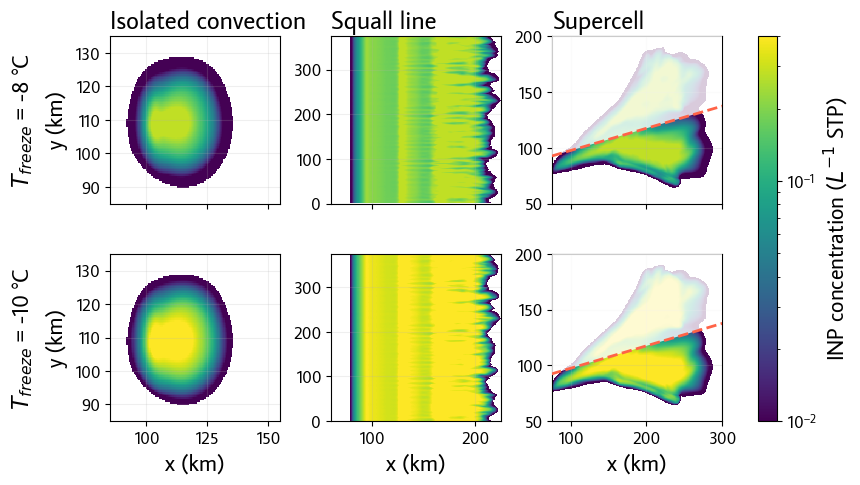

In [ ]:
cm.plotting.start_figure("surface_inp_concentrations")

this_fig_freezing_temps = [-8, -10]

fig, axs = plt.subplots(
    ncols=3,
    nrows=len(this_fig_freezing_temps),
    figsize=(8, 2.2 * len(this_fig_freezing_temps)),
    sharex="col",
    sharey="col",
)

ax_lims = {
    "ic_wk": {"x": [85000, 155000], "y": [85000, 135000]},
    "sl_wk": {"x": [60000, 225000], "y": None},
    "sc_wk": {"x": [75000, 300000], "y": [50000, 200000]},
}


def lm_polygon():
    return plt.Polygon(
        [
            (storm_ds["x"].min(), blt.sc_wk_right_mover_boundary(storm_ds["x"].min())),
            (storm_ds["x"].min(), storm_ds["y"].max()),
            (storm_ds["x"].max(), storm_ds["y"].max()),
            (storm_ds["x"].max(), blt.sc_wk_right_mover_boundary(storm_ds["x"].max())),
        ],
        closed=True,
        facecolor=(1, 1, 1, 0.8),
        edgecolor="tomato",
        linestyle="dashed",
        linewidth=2,
        zorder=999,
    )


for ax in axs[-1, :]:
    ax.set_xlabel("x (km)")

during_rain_times = {"ic_wk": 100, "sl_wk": 180, "sc_wk": 180}

for storm_ix, (storm, storm_ds) in enumerate(storm_dss.items()):
    axs[0, storm_ix].set_title(blt.STORM_LABELS[storm])
    for freezing_temp_ix, freezing_temp in enumerate(this_fig_freezing_temps):
        ax = axs[freezing_temp_ix, storm_ix]
        pc = ax.pcolormesh(
            storm_ds["x"],
            storm_ds["y"],
            p_to_inp(
                storm_ds.sel(
                    {"time": blt.minutes_to_simulation_time(during_rain_times[storm])}
                )["ACCPR"],
                freezing_temp,
            ),
            norm=colors.LogNorm(vmin=1e-2, vmax=4e-1),
            name=f"storm-{storm}_freezingtemp-{freezing_temp}_inps",
        )
        # cbar = plt.colorbar(pc, ax=ax)
        # cbar.ax.set_ylabel("#/L")
        ax.set_xlim(ax_lims[storm]["x"])
        ax.set_ylim(ax_lims[storm]["y"])
        if storm == "sc_wk":
            ax.add_patch(lm_polygon())
        cm.plotting.scale_axes_ticks(ax)
        if storm_ix == 0:
            ax.set_ylabel("y (km)")
            cm.plotting.add_row_header_auto(ax, rf"$T_{{freeze}}$ = {freezing_temp} °C")

cb = fig.colorbar(pc, ax=axs, fraction=0.1)
cb.ax.set_ylabel(r"INP concentration ($L^{-1}$ STP)")
save_figure_and_data()

In [ ]:
fig, ax = plt.subplots()

for storm, storm_ds in {"ic_wk": storm_dss["ic_wk"]}.items():
    pc = ax.pcolormesh(
        storm_ds["x"], storm_ds["y"], storm_ds.isel({"time": -1})["ACCPR"].values
    )
    plt.colorbar(pc, ax=ax)
    ax.set_xlim([75000, 150000])
    ax.set_ylim([90000, 125000])

In [ ]:
fig, ax = plt.subplots()

for storm, storm_ds in {"ic_wk": storm_dss["ic_wk"]}.items():
    pc = ax.pcolormesh(
        storm_ds["x"],
        storm_ds["y"],
        storm_ds.sel({"time": blt.minutes_to_simulation_time(100)})[
            "PCPRR_mm_hr"
        ].values,
    )
    plt.colorbar(pc, ax=ax)
    ax.set_xlim([75000, 150000])
    ax.set_ylim([90000, 125000])

In [ ]:
# Slopes of INP enhancement (#/L) vs cumulative precip (mm), in log-log space
# Keys are the INP freezing temp in °C
# Valid over the range 0.001 mm to 9.45 mm
mignani_inp_ll_slopes_by_ftemp = {
    "-25°C": 0.44,
    "-23°C": 0.46,
    "-20°C": 0.59,
    "-18°C": 0.65,
    "-15°C": 0.33,
    "-13°C": 0.41,
    "-10°C": 0.50,
    "-8°C": 0.68,
}

mignani_inp_ll_intercepts_by_ftemp = {
    "-25°C": 0.046,
    "-23°C": 0.031,
    "-20°C": 0.014,
    "-18°C": 0.008,
    "-15°C": 0.032,
    "-13°C": 0.019,
    "-10°C": 0.008,
    "-8°C": 0.0012,
}
mignani_inp_ll_slopes_valid_range = [0.001, 9.45]

# mignani_inp_ll_slopes_by_ftemp = {
#     -25: 0.699,
#     -23: 0.602,
#     -20: 0.477,
#     -18: 0.495,
#     -15: 0.699,
#     -13: 0.766,
#     -10: 0.796,
#     -8: 0.824,
# }
# mignani_inp_ll_intercepts_by_ftemp = {
#     -25: 0.0100,
#     -23: 0.0200,
#     -20: 0.0400,
#     -18: 0.0800,
#     -15: 0.0500,
#     -13: 0.0600,
#     -10: 0.0800,
#     -8: 0.0015,
# }

# Calculate value at 9.45 mm for -8°C case
log_precip = 9.45
log_dinp_at_max = mignani_inp_ll_intercepts_by_ftemp[
    "-8°C"
] + mignani_inp_ll_slopes_by_ftemp["-8°C"] * (0.001 / log_precip)
dinp_at_max = log_dinp_at_max
print(f"At 9.45 mm precip, -8°C INP enhancement: {dinp_at_max:.4f} #/L")

In [ ]:
# Slopes of INP enhancement (#/L) vs cumulative precip (mm), in log-log space
# Keys are the INP freezing temp in °C
# Valid over the range 0.001 mm to 9.45 mm
mignani_inp_ll_slopes_by_ftemp = {
    -25: 0.699,
    -23: 0.602,
    -20: 0.477,
    -18: 0.495,
    -15: 0.699,
    -13: 0.766,
    -10: 0.796,
    -8: 0.824,
}
mignani_inp_ll_intercepts_by_ftemp = {
    -25: 0.0100,
    -23: 0.0200,
    -20: 0.0400,
    -18: 0.0800,
    -15: 0.0500,
    -13: 0.0600,
    -10: 0.0800,
    -8: 0.0015,
}

# Calculate value at 9.45 mm for -8°C case
log_precip = np.log10(9.45)
log_dinp_at_max = (
    mignani_inp_ll_intercepts_by_ftemp[-8]
    + mignani_inp_ll_slopes_by_ftemp[-8] * log_precip
)
dinp_at_max = 10**log_dinp_at_max
print(f"At 9.45 mm precip, -8°C INP enhancement: {dinp_at_max:.4f} #/L")
# These are actual values in mm, not in log-log space
mignani_inp_ll_slopes_valid_range = [0.001, 9.45]


def accpr_to_dinp(accpr, raise_if_extrapolation=False):
    print(accpr)
    if (accpr < mignani_inp_ll_slopes_valid_range[0]) or (
        accpr > mignani_inp_ll_slopes_valid_range[1]
    ):
        if raise_if_extrapolation:
            raise ValueError(
                "Precip passed to accpr_to_dinp is outside of validity range"
            )
        else:
            # In this case, we just say no enhancement below the minimum and clip it
            # to the max valid value if it's above the maximum
            if accpr < mignani_inp_ll_slopes_valid_range[0]:
                return {temp: 0 for temp in mignani_inp_ll_slopes_by_ftemp.keys()}
            else:
                accpr = mignani_inp_ll_slopes_valid_range[1]
    # Convert to log space
    accpr = np.log10(accpr)
    return {
        temp: (
            10
            ** (  # Convert from log-space back to an actual value
                mignani_inp_ll_intercepts_by_ftemp[temp]
                + mignani_inp_ll_slopes_by_ftemp[temp] * accpr
            )
        )
        for temp in mignani_inp_ll_slopes_by_ftemp.keys()
    }


def accpr_to_dinp_vectorized(accpr_da, raise_if_extrapolation=False):
    """
    Vectorized version that works natively with xarray DataArrays.
    Returns a DataArray with a new 'temperature' dimension.
    """
    # Get temperature values and sort them for consistent ordering
    temps = sorted(mignani_inp_ll_slopes_by_ftemp.keys())

    # Convert dictionaries to arrays for vectorized operations
    slopes = np.array([mignani_inp_ll_slopes_by_ftemp[temp] for temp in temps])
    intercepts = np.array([mignani_inp_ll_intercepts_by_ftemp[temp] for temp in temps])

    # Handle out-of-range values
    if raise_if_extrapolation:
        if (
            (accpr_da < mignani_inp_ll_slopes_valid_range[0])
            | (accpr_da > mignani_inp_ll_slopes_valid_range[1])
        ).any():
            raise ValueError(
                "Precip passed to accpr_to_dinp is outside of validity range"
            )

    # Set values below minimum to return 0 enhancement
    below_min = accpr_da < mignani_inp_ll_slopes_valid_range[0]

    # Clip values above maximum
    accpr_clipped = xr.where(
        accpr_da > mignani_inp_ll_slopes_valid_range[1],
        mignani_inp_ll_slopes_valid_range[1],
        accpr_da,
    )

    # Convert to log space
    accpr_log = np.log10(accpr_clipped)

    # Add new temperature dimension
    accpr_log_expanded = accpr_log.expand_dims(temperature=temps)

    # Create DataArrays for slopes and intercepts with proper coordinates
    slopes_da = xr.DataArray(
        slopes, dims=["temperature"], coords={"temperature": temps}
    )
    intercepts_da = xr.DataArray(
        intercepts, dims=["temperature"], coords={"temperature": temps}
    )

    # Vectorized calculation using xarray broadcasting
    log_dinp = intercepts_da + slopes_da * accpr_log_expanded

    # Convert back from log space
    dinp = 10**log_dinp

    # Handle below-minimum case by setting to 0
    if not raise_if_extrapolation:
        below_min_expanded = below_min.expand_dims(temperature=temps)
        dinp = xr.where(below_min_expanded, 0, dinp)

    return dinp


# Example usage - vectorized approach
for storm, storm_ds in {"ic_wk": storm_dss["ic_wk"]}.items():
    dinp_vectorized = accpr_to_dinp_vectorized(storm_ds.isel({"time": -1})["ACCPR"])

    # Calculate global min/max for consistent colormap
    vmin = float(dinp_vectorized.min())
    vmax = float(dinp_vectorized.max())

    fig, axs = plt.subplots(
        nrows=2,
        ncols=4,
        figsize=(12, 6),
        layout="constrained",
        sharex=True,
        sharey=True,
    )
    for temperature_ix, temperature in enumerate(dinp_vectorized["temperature"].values):
        this_temp_ds = dinp_vectorized.sel({"temperature": temperature})
        ax = axs.flatten()[temperature_ix]
        im = ax.pcolormesh(
            this_temp_ds["x"],
            this_temp_ds["y"],
            this_temp_ds.values,
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(f"{temperature}°C")

    # Add a shared colorbar
    fig.colorbar(im, ax=axs, shrink=0.8, label="INP Enhancement (#/L)")

    # print(f"Shape: {dinp_vectorized.shape}")
    # print(f"Dimensions: {dinp_vectorized.dims}")
    # display(dinp_vectorized)
    break  # Just show the first one for demonstration

In [ ]:
acc_tracer_vars = [f"ACC{tracer}" for tracer in blt.RS_TRACERS]


def to_features_and_target(ds):
    # Copy the dataset
    ds = ds.copy()
    # Convert rain to mm
    ds["ACCPR"] = (
        (ds["ACCPR"] * units("kg/m^2") / mpconstants.density_water)
        .pint.to("mm")
        .pint.dequantify()
    )
    # Reshape the dataset to have (x, y, time) as rows and the 5 tracer variables as columns
    lr_ds = ds[acc_tracer_vars + ["ACCPR"]].stack(sample=[...])
    features_arr = lr_ds[acc_tracer_vars].to_array().values.T
    target_arr = lr_ds["ACCPR"].values
    return features_arr, target_arr


lms = {}
for storm, storm_ds in {"ic_wk": storm_dss["ic_wk"]}.items():
    storm_features_arr, storm_target_arr = to_features_and_target(storm_ds)
    # Filter to where there's some rain
    rain_mask = storm_target_arr > 0
    rain_features_arr = storm_features_arr[rain_mask]
    rain_target_arr = storm_target_arr[rain_mask]

    print("Fitting...")
    lm = LinearRegression().fit(rain_features_arr, rain_target_arr)
    print("Scoring...")
    r2 = lm.score(rain_features_arr, rain_target_arr)
    print(f"R^2 is {r2}")
    # Plot the residuals
    storm_predicted = lm.predict(storm_features_arr)
    fig, ax = plt.subplots()
    ax.hist2d(storm_target_arr, storm_predicted, bins=50, alpha=0.7)
    ax.set_xlabel("Actual rainfall (mm)")
    ax.set_ylabel("Predicted rainfall (mm)")
    ax.set_title(f"Actual vs Predicted (R² = {r2:.4f})")
    # ax.set_xscale('log')
    ax.set_yscale("log")

    # Test on light rain and heavy rain
    fig, axs = plt.subplots(ncols=2, figsize=(8, 3))
    for this_time_ix, this_time in enumerate([75, 100]):
        this_time_features_arr, this_time_target_arr = to_features_and_target(
            storm_ds.sel({"time": blt.minutes_to_simulation_time(this_time)})
        )
        this_time_prediction = lm.predict(this_time_features_arr)

        ax = axs[this_time_ix]
        pc = ax.pcolormesh(
            (
                (this_time_prediction - this_time_target_arr) / this_time_target_arr
            ).reshape((len(storm_ds["y"]), len(storm_ds["x"]))),
            vmin=0,
            vmax=5,
        )
        ax.set_xlim([200, 250])
        ax.set_ylim([190, 250])
        plt.colorbar(pc, ax=ax)
    lms[storm] = lm
lms

## Lofting to upper levels

### Setup

#### Calculate upper-level tracer concentrations

In [30]:
# Make a preprocessing step like what we do to create the tracer concentration files,
# but without filtering to in-updraft gridpoints
def preprocess_ul_tracers(height_threshold):
    dfs = {}
    for storm, ds in tqdm(storm_dss.items()):
        print("Preprocessing...")
        ds = ds.copy()
        # Make a list of all of the tracer variables
        all_current_tracer_vars = blt.FS_TRACERS + blt.RS_TRACERS + ["total_fs_tracer"]
        # Add the accumulated variables
        all_acc_tracer_vars = ["ACC" + tracer for tracer in all_current_tracer_vars]
        # Make number concentration versions of the current tracers
        for tracer in all_current_tracer_vars:
            ds[tracer + "_nc"] = ds[tracer] * ds["air_mass"]
            # See comments in blt.calculate_tracer_profile_ds for discussion on why
            # this is how we calculate the ACC nc variables
            ds["ACC" + tracer + "_nc"] = (
                ds["ACC" + tracer] * ds.isel({"z": 1, "time": 0})["air_mass"]
            )
        # Limit to above 10km and doesn't have to be in-updraft
        ds = ds.sel({"z": slice(height_threshold, None, None)})
        ds = ds.where(ds["in_analysis"]).sum(["x", "y", "z"])
        # Convert to a dataframe
        df = (
            ds[[x for x in ds.data_vars if "tracer" in x.lower()] + ["air_mass"]]
            .to_dataframe()
            .reset_index()
        )
        dfs[storm] = df
    return dfs


ul_tracer_dfs = {}
for z_km in blt.ALL_UL_Z_THRESHOlDS:
    ul_tracer_dfs[z_km] = cm.utils.read_or_cache_to(
        blt.DERIVED_DIR / f"ul_tracer_totals_z-{z_km}000.pkl"
    )(preprocess_ul_tracers)(z_km * 1000)

Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_tracer_totals_z-7000.pkl
Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_tracer_totals_z-8000.pkl
Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_tracer_totals_z-9000.pkl
Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_tracer_totals_z-10000.pkl


#### Read 2 second RAMS output

In [8]:
# Get the index of the z value from the full datasets
z_ul_ix = np.argmin(np.abs(storm_dss["ic_wk"]["z"].values - 10000))
print(z_ul_ix)
print(storm_dss["ic_wk"]["z"].values[z_ul_ix])

56
10083.67578125


In [ ]:
## 2 second RAMS output
reload(cm.rams)
reload(blt)

# Define the list of RAMS output filenames we'll read in
# Can specify this manually or just use a glob
rams_lite_input_filename_glob = "a-L-*.h5"

rams_lite_input_dim_names_kwargs = (
    {
        "dim_names": {
            "phony_dim_0": "y",
            "phony_dim_1": "x",
            "phony_dim_2": "p",
            "phony_dim_3": "z",
        }
    }
    if rams_lite_input_filename_glob.startswith("a-L")
    else {}
)

# Match the datetimes we'll read in based on what's in the trajectories
rams_lite_input_dts = (
    pd.date_range(
        start=blt.SIMULATION_START_TIME,
        end=blt.SIMULATION_END_TIME,
        freq="2s",
    )
    .strftime(cm.rams.RAMS_DT_STRFTIME_STR)
    .values
)


# lite_dss = {}

for storm_name in tqdm(list(blt.STORM_LABELS.keys())):
    if storm_name != 'sc_wk':
        continue
    rams_lite_input_filenames = [
        blt.RAMS_OUTPUT_DIRS[storm_name].joinpath(f"a-L-{x}-g1.h5")
        for x in rams_lite_input_dts
    ]
    assert all([x.exists() for x in rams_lite_input_filenames])
    # Read in the RAMS output
    storm_ds = cm.rams.read_rams_output(
        input_filenames=rams_lite_input_filenames,
        time_dim_name="time",
        units=False,
        # keep_vars=['WC', 'THETA', 'PI', ]
        dim_names={"phony_dim_0": "y", "phony_dim_1": "x", "phony_dim_2": "p"},
        preprocess=lambda ds: ds.isel({"phony_dim_3": z_ul_ix}, drop=False),
    )

    # Postprocess
    storm_ds = blt.postprocess_storm_ds(storm_ds, storm_name, lite=True)

    # Calculate air density on these manually since we don't have DN0
    # Need mixing ratio first
    storm_ds["mixing_ratio"] = mpc.mixing_ratio(
        partial_press=storm_ds["vapor_pressure"] * units("hPa"),
        total_press=storm_ds["P"] * units("hPa"),
    ).pint.dequantify()
    storm_ds["air_density"] = (
        mpc.density(
            pressure=storm_ds["P"] * units("hPa"),
            temperature=storm_ds["T"] * units("K"),
            mixing_ratio=storm_ds["mixing_ratio"],
        )
        .pint.to("kg/m^3")
        .pint.dequantify()
    )

    # Store
    lite_dss[storm_name] = storm_ds

storm_ds

  0%|          | 0/3 [00:00<?, ?it/s]

Reading and concatenating 5401 RAMS individual timestep outputs...


In [ ]:
lite_dss = {
    k: v.chunk({"x": len(storm_ds["x"].values), "y": len(storm_ds["y"].values)})
    for k, v in lite_dss.items()
}

<xarray.Dataset> Size: 310GB
Dimensions:                    (time: 5401, y: 440, x: 750, p: 2)
Coordinates:
  * x                          (x) float64 6kB 0.0 500.0 ... 3.74e+05 3.745e+05
  * y                          (y) float64 4kB 0.0 500.0 ... 2.19e+05 2.195e+05
  * time                       (time) datetime64[ns] 43kB 1991-04-26T21:00:00...
    t_minutes                  (time) float64 43kB dask.array<chunksize=(5401,), meta=np.ndarray>
Dimensions without coordinates: p
Data variables: (12/45)
    GLAT                       (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    GLON                       (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    PATCH_AREA                 (time, p, y, x) float32 14GB dask.array<chunksize=(1, 2, 440, 750), meta=np.ndarray>
    PCPRH                      (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    PCPRR                      (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    PCPVH                      (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    ...                         ...
    THETA_bsr                  (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    theta_deficit              (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    in_analysis                (x, y) bool 330kB dask.array<chunksize=(750, 440), meta=np.ndarray>
    PCPRR_mm_hr                (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    mixing_ratio               (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>
    air_density                (time, y, x) float32 7GB dask.array<chunksize=(1, 440, 750), meta=np.ndarray>

#### Calculate upper level mass fluxes

In [ ]:
# def temp_calculate_flux(ds, mask):
#     ul_flux = (
#         ds["WC"] * ds["air_density"] * 500**2 * 2  # m/s  # kg/m^3  # m^2  # s
#     ).where(
#         mask
#     )  # Gives kg
#     return ul_flux.sum(["x", "y"]).cumsum("time")


# ic_z10km_ds = lite_dss["ic_wk"]#.sel({"z": 10_000}, method="nearest")

# # Compute the mask first
# print("Computing mask")
# is_upward = (ic_z10km_ds["WC"] >= 0).compute()

# print("Calculating upward flux")
# temp_ic_up = temp_calculate_flux(ds=ic_z10km_ds, mask=is_upward).compute()

# print("Calculating downward flux")
# temp_ic_down = temp_calculate_flux(ds=ic_z10km_ds, mask=~is_upward).compute()

Computing mask


/home/cmdavis4/programs/miniforge3/envs/tracer_paper2/lib/python3.12/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 12.65 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Calculating upward flux


/home/cmdavis4/programs/miniforge3/envs/tracer_paper2/lib/python3.12/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 1.70 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Calculating downward flux


/home/cmdavis4/programs/miniforge3/envs/tracer_paper2/lib/python3.12/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 1.70 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [25]:
# fig, axs = plt.subplots(ncols=2, figsize=((8, 3)))
# up_to_plot = temp_ic_up.sel({'time': storm_dss['ic_wk']['time'].values})
# down_to_plot = temp_ic_down.sel({'time': storm_dss['ic_wk']['time'].values})
# axs[0].plot(up_to_plot['t_minutes'].values, up_to_plot.values)
# axs[1].plot(down_to_plot['t_minutes'].values, -down_to_plot.values)

# axs[0].plot(ul_flux_dss[10]['ic_wk']['t_minutes'], ul_flux_dss[10]['ic_wk']['cumu_upward_mass_flux'])
# axs[1].plot(ul_flux_dss[10]['ic_wk']['t_minutes'], -ul_flux_dss[10]['ic_wk']['cumu_downward_mass_flux'])
# # ax.set_xlim([125, 175])

In [14]:
# def fix_flux(inpath, outpath):
#     with inpath.open("rb") as f:
#         (
#             total_upward_ul_mass_fluxes,
#             cumu_upward_ul_mass_fluxes,
#             total_downward_ul_mass_fluxes,
#             cumu_downward_ul_mass_fluxes,
#         ) = pkl.load(f)

#     flux_dss = {}
#     for storm in blt.STORM_LABELS:

#         cumu_upward_ul_mass_fluxes[storm].name = "cumu_upward_mass_flux"
#         cumu_downward_ul_mass_fluxes[storm].name = "cumu_downward_mass_flux"
#         flux_dss[storm] = xr.merge([cumu_upward_ul_mass_fluxes[storm], cumu_downward_ul_mass_fluxes[storm]])
#     with outpath.open('wb') as f:
#         pkl.dump(flux_dss, f)

# fix_flux(Path("/home/cmdavis4/projects/tracer_paper/data/derived/ul_mass_fluxes_z-10000_old.pkl"), Path("/home/cmdavis4/projects/tracer_paper/data/derived/ul_mass_fluxes_z-10000.pkl"))

In [ ]:
   ul_flux = (
        ds["WC"] * ds["air_density"] * 500**2 * 2  # m/s  # kg/m^3  # m^2  # s
    ).where(
        mask
    )  # Gives kg
    return ul_flux.sum(["x", "y"]).cumsum("time")


ic_z10km_ds = lite_dss["ic_wk"]#.sel({"z": 10_000}, method="nearest")


In [ ]:
# Make a function for calculating the mass flux
def _calculate_flux(ds, mask):
    ul_flux = (
        ds["WC"] * ds["air_density"] * 500**2 * 2  # m/s  # kg/m^3  # m^2  # s
    ).where(
        mask
    )  # Gives kg
    return (
        ul_flux.sum(["x", "y"])
        .cumsum("time")
        .sel({"time": storm_dss[storm]["time"].values})
    )


def _calculate_ul_fluxes_single_storm(this_ul_ds):
    # Precompute the mask
    # ================================
    print("Calculating mask")
    is_upward = (this_ul_ds["WC"] > 0).compute()

    # Calculate positive (upward) flux across this vertical level
    # ================================
    print("Calculating upward flux")
    this_upward_flux = _calculate_flux(ds=this_ul_ds, mask=is_upward).compute()

    # Calculate negative (downward) flux across this vertical level
    # ================================
    print("Calculating downward flux")
    this_downward_flux = _calculate_flux(ds=this_ul_ds, mask=~is_upward).compute()

    this_upward_flux.name = "cumu_upward_mass_flux"
    this_downward_flux.name = "cumu_downward_mass_flux"
    return xr.merge([this_upward_flux, this_downward_flux])


def calculate_ul_fluxes(height_threshold=None):
    flux_dss = {}
    for storm, lite_ds in tqdm(lite_dss.items()):
        if height_threshold:
            # Assume we haven't limited to a single height in preprocessing
            this_ul_ds = lite_ds.sel(
                {"z": height_threshold}, method="nearest", drop=True
            )
        else:
            # Assume we have
            this_ul_ds = lite_ds.copy()

        flux_dss[storm] = _calculate_ul_fluxes_single_storm(this_ul_ds=this_ul_ds)

    return flux_dss


ul_flux_dss = {}
for z_km in blt.ALL_UL_Z_THRESHOlDS:
    ul_flux_dss[z_km] = cm.utils.read_or_cache_to(
        blt.DERIVED_DIR / f"ul_mass_fluxes_z-{z_km}000.pkl"
    )(calculate_ul_fluxes)(height_threshold=z_km * 1000)

# Last runtime 1024 minutes

Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_mass_fluxes_z-7000.pkl
Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_mass_fluxes_z-8000.pkl
Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_mass_fluxes_z-9000.pkl
Read result from /home/cmdavis4/projects/tracer_paper/data/derived/ul_mass_fluxes_z-10000.pkl


In [ ]:
# Fix the supercell for 10km
fixed_sc_flux = _calculate_ul_fluxes_single_storm(this_ul_ds=lite_dss["sc_wk"])
fixed_sc_flux

KeyError: 'sc_wk'

### Analysis

#### Identification of upper level cutoff

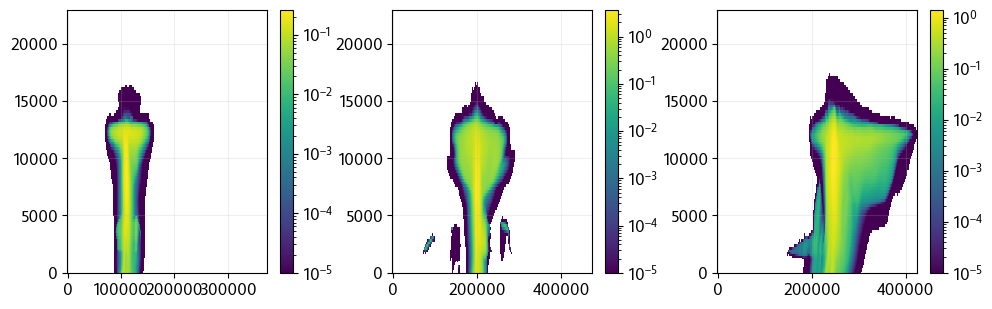

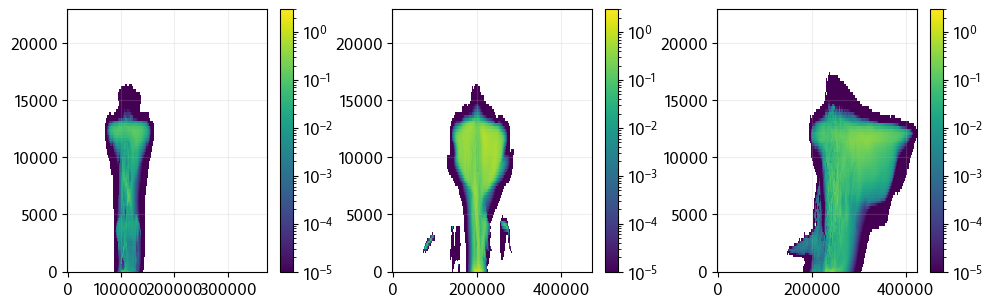

In [ ]:
height_cutoff_times = {"ic_wk": 100, "sl_wk": 180, "sc_wk": 180}

cm.plotting.start_figure("upper_level_height_cutoff")


fig, axs = plt.subplots(ncols=3, figsize=(10, 3))
for storm_ix, (storm, storm_ds) in enumerate(storm_dss.items()):
    # Limit to the right time
    storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(height_cutoff_times[storm])}, drop=True
    )
    # Look at condensate
    ax = axs[storm_ix]
    pc = ax.pcolormesh(
        storm_ds["x"],
        storm_ds["z"],
        storm_ds["R_condensate"].sum("y").values,
        norm=colors.LogNorm(vmin=1e-5),
    )
    fig.colorbar(pc, ax=ax)

fig, axs = plt.subplots(ncols=3, figsize=(10, 3))
for storm_ix, (storm, storm_ds) in enumerate(storm_dss.items()):
    storm_ds = storm_ds.sel(
        {"time": blt.minutes_to_simulation_time(height_cutoff_times[storm])}, drop=True
    )
    # Look at condensate without strong vertical motion
    storm_ds = storm_ds.where((storm_ds["WC"] < 0.5) & (storm_ds["WC"] > -0.5))
    ax = axs[storm_ix]
    pc = ax.pcolormesh(
        storm_ds["x"],
        storm_ds["z"],
        storm_ds["R_condensate"].sum("y").values,
        norm=colors.LogNorm(vmin=1e-5, vmax=3),
    )
    fig.colorbar(pc, ax=ax)

#### Fluxes vs time

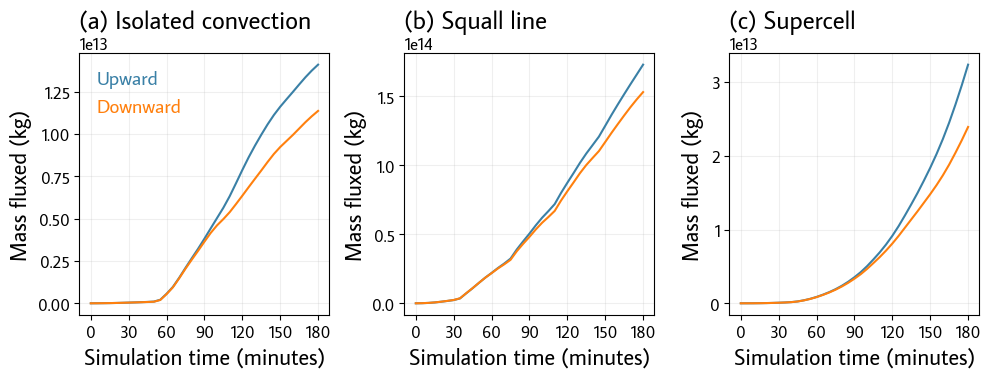

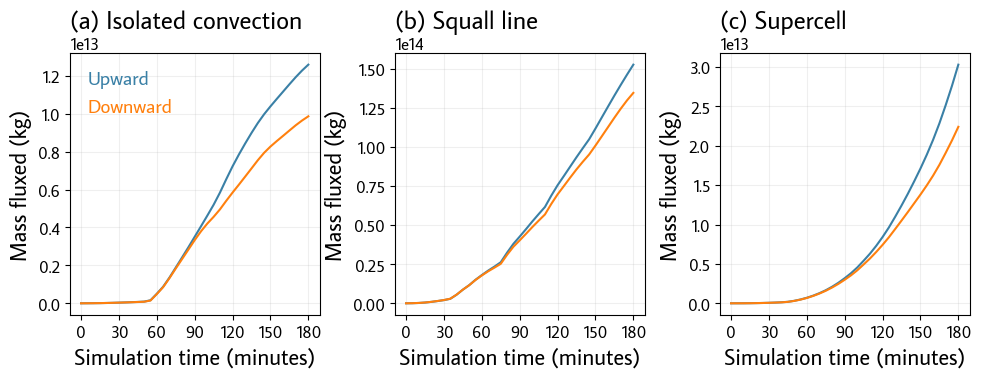

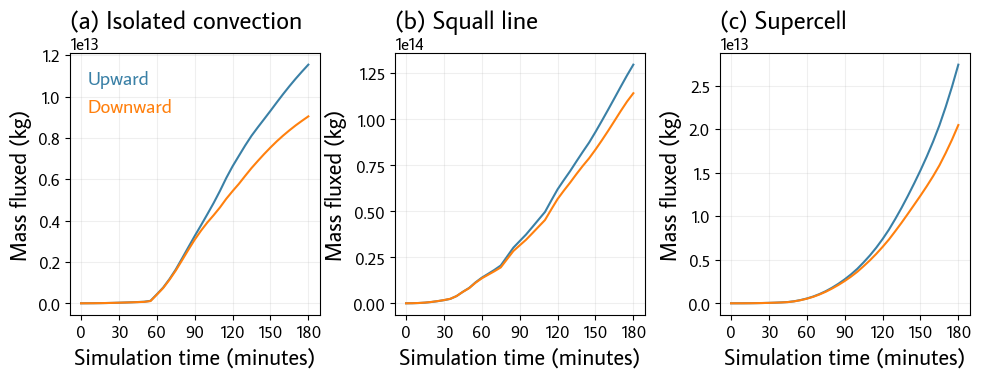

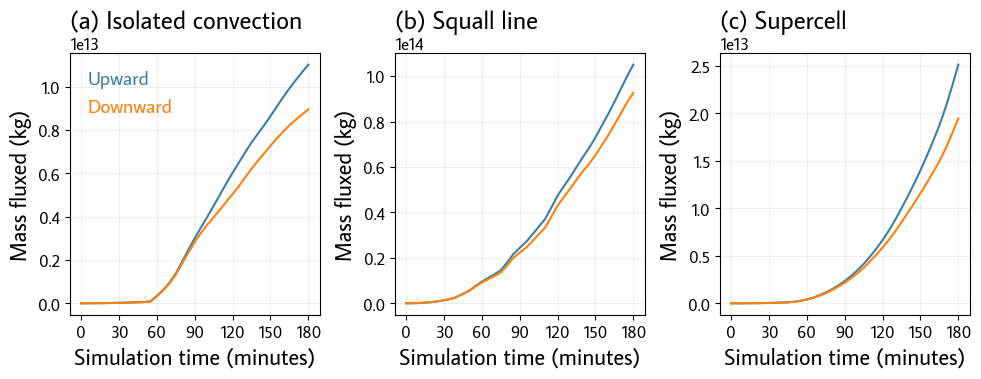

In [33]:
for z_km in blt.ALL_UL_Z_THRESHOlDS:

    cm.plotting.start_figure(f"ul_mass_fluxes_z-{z_km}000")

    fig, axs = plt.subplots(ncols=3, figsize=(10, 3))

    for storm_ix, storm in enumerate(blt.STORM_NAMES):
        ax = axs.flatten()[storm_ix]
        ax.plot(
            storm_dss[storm]["t_minutes"].values,
            ul_flux_dss[z_km][storm]["cumu_upward_mass_flux"],
            label="Upward",
            name=f"{storm}_upward_mass_flux",
        )
        ax.plot(
            storm_dss[storm]["t_minutes"].values,
            -1 * ul_flux_dss[z_km][storm]["cumu_downward_mass_flux"],
            label="Downward",
            name=f"{storm}_downward_mass_flux",
        )
        ax.set_ylabel("Mass fluxed (kg)")
        blt.label_x_axis(ax)
        ax.set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))
    cm.plotting.clean_legend(axs[0])

    save_figure_and_data()

#### Net flux ratio

In [28]:
for z_km in blt.ALL_UL_Z_THRESHOlDS:
    print(z_km)
    for storm in blt.STORM_NAMES:
        print(storm)
        print(
            (
                ul_flux_dss[z_km][storm]["cumu_downward_mass_flux"]
                / -ul_flux_dss[z_km][storm]["cumu_upward_mass_flux"]
            )
            .isel({"time": -1})
            .values
        )
    print("")

7
ic_wk
0.8062031
sl_wk
0.88500834
sc_wk
0.7388487

8
ic_wk
0.78352195
sl_wk
0.8817218
sc_wk
0.73945063

9
ic_wk
0.7832569
sl_wk
0.880272
sc_wk
0.74701655

10
ic_wk
0.81278175
sl_wk
0.88177794
sc_wk
0.77493864



#### Normalized tracer concentrations

/tmp/ipykernel_849069/1045567667.py:14: RuntimeWarning: invalid value encountered in divide
  this_ul_tracer_df[f"total_fs_tracer_nc"].values
/tmp/ipykernel_849069/1045567667.py:24: RuntimeWarning: invalid value encountered in divide
  this_ul_tracer_df[f"{tracer}_nc"].values
/home/cmdavis4/programs/miniforge3/envs/tracer_paper2/lib/python3.12/site-packages/xarray/core/computation.py:818: RuntimeWarning: invalid value encountered in divide
  result_data = func(*input_data)
/tmp/ipykernel_849069/1045567667.py:14: RuntimeWarning: invalid value encountered in divide
  this_ul_tracer_df[f"total_fs_tracer_nc"].values
/tmp/ipykernel_849069/1045567667.py:24: RuntimeWarning: invalid value encountered in divide
  this_ul_tracer_df[f"{tracer}_nc"].values
/home/cmdavis4/programs/miniforge3/envs/tracer_paper2/lib/python3.12/site-packages/xarray/core/computation.py:818: RuntimeWarning: invalid value encountered in divide
  result_data = func(*input_data)
/tmp/ipykernel_849069/1045567667.py:14: Runt

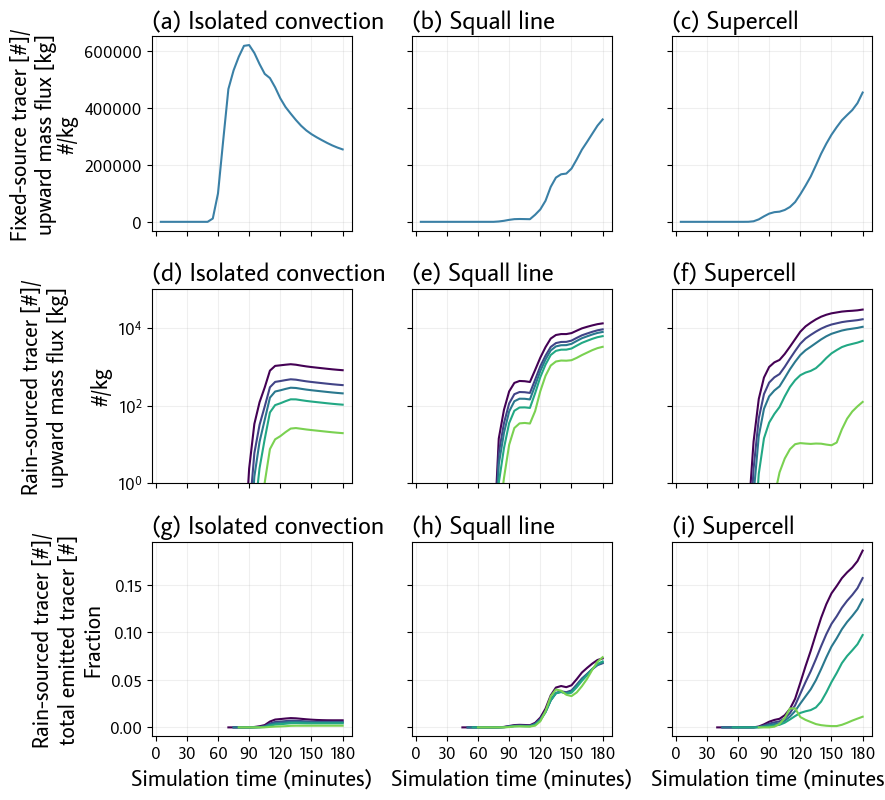

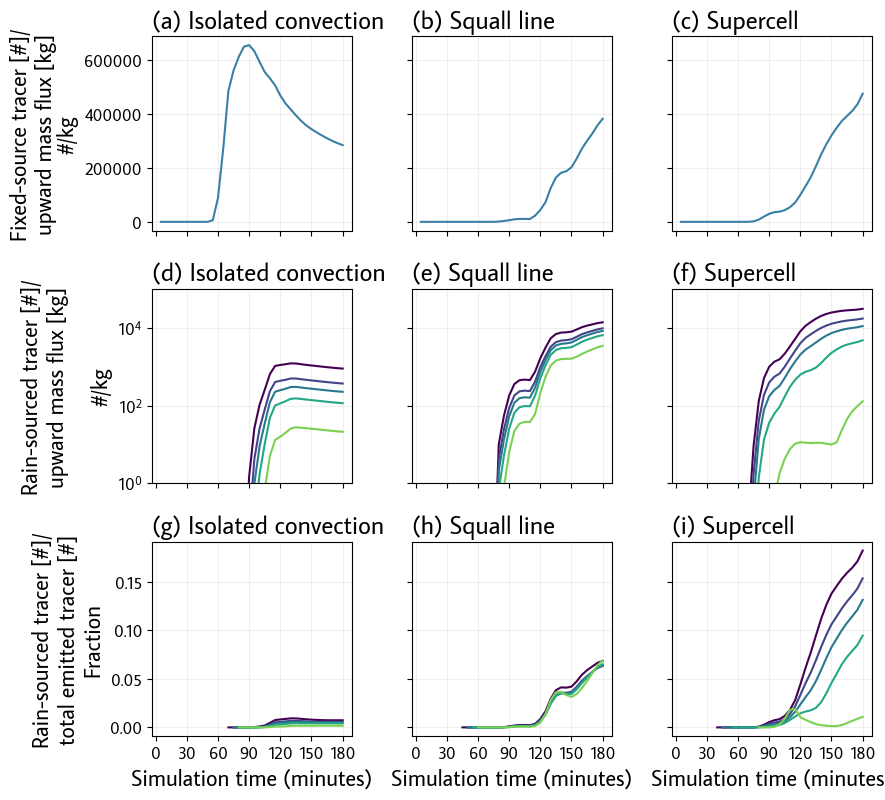

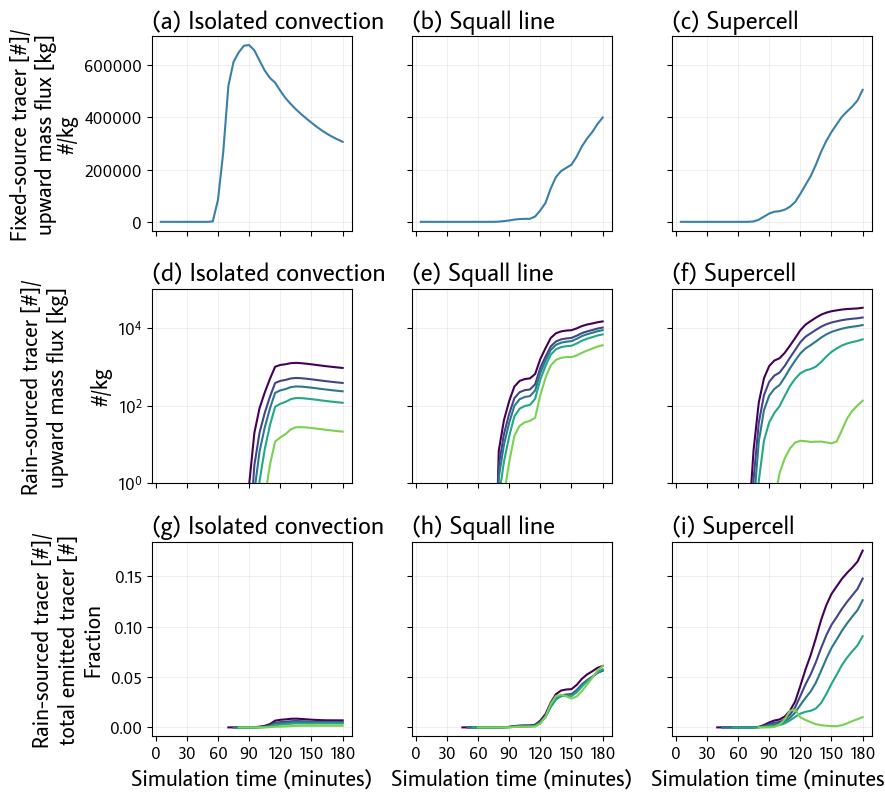

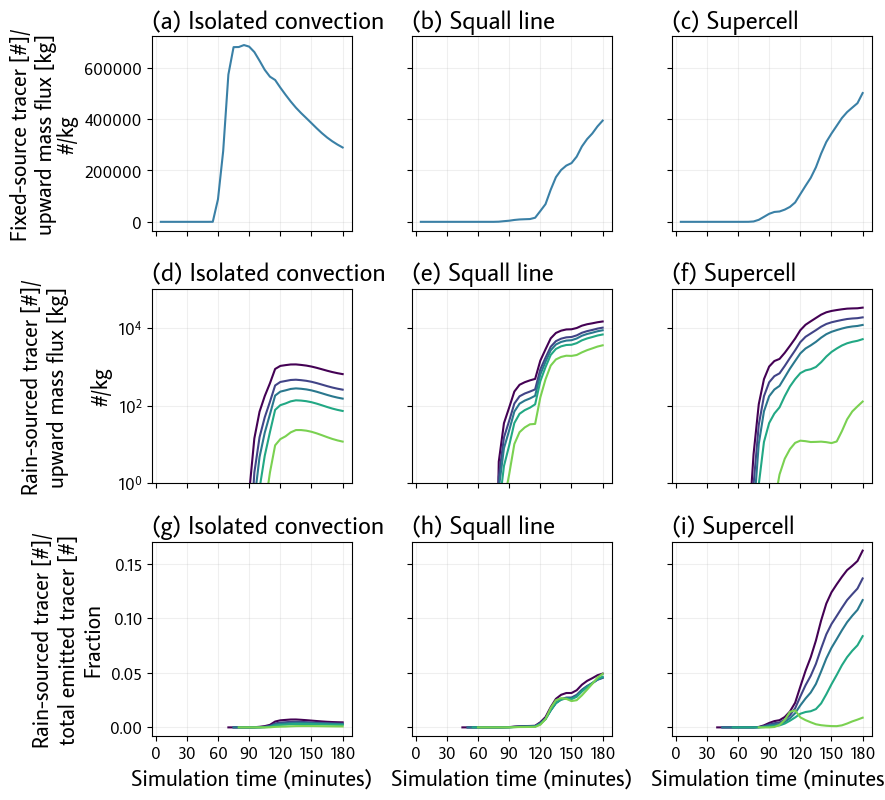

In [32]:
for z_km in blt.ALL_UL_Z_THRESHOlDS:

    cm.plotting.start_figure(f"fxx_tracer_entrainment_{z_km}km", verbose=False)

    # Start with fs only
    # Do total, normalized by max updraft mass, normalized by max anvil size

    fig, axs = plt.subplots(ncols=3, nrows=3, figsize=(8, 8), sharex=True, sharey="row")

    for storm_ix, (storm, this_ul_tracer_df) in enumerate(ul_tracer_dfs[z_km].items()):
        # Fixed-source
        axs[0, storm_ix].plot(
            this_ul_tracer_df["t_minutes"],
            this_ul_tracer_df[f"total_fs_tracer_nc"].values
            / ul_flux_dss[z_km][storm]["cumu_upward_mass_flux"].values,
            name=f"storm-{storm}_tracer-fstracernc_normalized-flux",
        )
        axs[0, storm_ix].set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))

        for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
            # Normalized by max updraft mass
            axs[1, storm_ix].plot(
                this_ul_tracer_df["t_minutes"],
                this_ul_tracer_df[f"{tracer}_nc"].values
                / ul_flux_dss[z_km][storm]["cumu_upward_mass_flux"].values,
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                name=f"storm-{storm}_tracer-rstracer{tracer.lower()}_normalized-flux",
            )

            axs[2, storm_ix].plot(
                this_ul_tracer_df["t_minutes"],
                this_ul_tracer_df[f"{tracer}_nc"].values
                / tracer_totals_profile_dss[storm][f"ACC{tracer}_nc"],
                color=mpl.colormaps[blt.PROGRESSIVE_CMAP](
                    tracer_ix / len(blt.RS_TRACERS)
                ),
                label=str(blt.RS_TRACER_THRESHOLDS_MM_HR[tracer_ix]) + " mm/hr",
                name=f"storm-{storm}_tracer-rstracer{tracer.lower()}_normalized-acc",
            )

        axs[1, storm_ix].set_title(
            blt.axes_title(3 + storm_ix, blt.STORM_LABELS[storm])
        )
        axs[2, storm_ix].set_title(
            blt.axes_title(6 + storm_ix, blt.STORM_LABELS[storm])
        )

    cm.plotting.add_row_header_auto(
        axs[0, 0], "Fixed-source tracer [#]/\nupward mass flux [kg]"
    )
    cm.plotting.add_row_header_auto(
        axs[1, 0], "Rain-sourced tracer [#]/\nupward mass flux [kg]"
    )
    cm.plotting.add_row_header_auto(
        axs[2, 0], "Rain-sourced tracer [#]/\ntotal emitted tracer [#]"
    )

    axs[0, 0].set_ylabel("#/kg")
    axs[1, 0].set_ylabel("#/kg")
    axs[2, 0].set_ylabel("Fraction")

    for ax in axs[-1, :].flatten():
        blt.label_x_axis(ax)

    for ax in axs[1:2].flatten():
        ax.set_yscale("log")
        ax.set_ylim([1e0, 1e5])

    save_figure_and_data()

##### End of simulation

In [ ]:
ul_tracer_dfs[10]["ic_wk"]

,time,ACCTRACERP001,ACCTRACERP002,ACCTRACERP003,ACCTRACERP004,ACCTRACERP005,ACCTRACERP006,ACCTRACERP007,ACCTRACERP008,ACCTRACERP009,...,TRACERP037_nc,TRACERP038_nc,TRACERP039_nc,TRACERP040_nc,TRACERP041_nc,TRACERP042_nc,total_fs_tracer_nc,ACCtotal_fs_tracer_nc,air_mass,t_minutes
0,1991-04-26 21:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,2.073416e+14,0.0
1,1991-04-26 21:05:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,1.692622e+19,2.073416e+14,5.0
2,1991-04-26 21:10:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,0.000000e+00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,3.385244e+19,2.073416e+14,10.0
3,1991-04-26 21:15:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,5.077866e+19,2.073416e+14,15.0
4,1991-04-26 21:20:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,6.770488e+19,2.073416e+14,20.0
5,1991-04-26 21:25:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,8.463110e+19,2.073416e+14,25.0
6,1991-04-26 21:30:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,1.015573e+20,2.073416e+14,30.0
7,1991-04-26 21:35:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,1.184835e+20,2.073416e+14,35.0
8,1991-04-26 21:40:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,1.354098e+20,2.073416e+14,40.0
9,1991-04-26 21:45:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,2.457180e+12,2.457180e+12,2.457180e+12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,1.523360e+20,2.073416e+14,45.0


In [ ]:
for z_km, this_z_dfs in ul_tracer_dfs.items():
    print(z_km)
    for storm_ix, (storm, this_ul_tracer_df) in enumerate(this_z_dfs.items()):
        print(storm)
        print(
            (
                this_ul_tracer_df["total_fs_tracer_nc"].iloc[-1]
                / ul_flux_dss[z_km][storm]["cumu_upward_mass_flux"].values[-1]
            )
            / (
                this_z_dfs["ic_wk"]["total_fs_tracer_nc"].iloc[-1]
                / ul_flux_dss[z_km]["ic_wk"]["cumu_upward_mass_flux"].values[-1]
            )
        )
    print("\n")

7
ic_wk
1.0
sl_wk
1.4141330033187776
sc_wk
1.7854758712340513


8
ic_wk
1.0
sl_wk
1.3424897434788274
sc_wk
1.6695031387071249


9
ic_wk
1.0
sl_wk
1.3027565986401592
sc_wk
1.6493106360679919


10
ic_wk
1.0
sl_wk
1.361433058724946
sc_wk
1.7324157522591412




In [ ]:
for storm_ix, (storm, this_ul_tracer_df) in enumerate(ul_tracer_dfs.items()):
    print(storm)
    display(
        (
            this_ul_tracer_df["total_fs_tracer_nc"].iloc[-1]
            / cumu_upward_ul_mass_fluxes[storm].values[-1]
        )
        / (
            ul_tracer_dfs["ic_wk"]["total_fs_tracer_nc"].iloc[-1]
            / cumu_upward_ul_mass_fluxes["ic_wk"].values[-1]
        )
    )

7
ic_wk
1.0
sl_wk
0.08152244848168434
sc_wk
0.43552969259544116


8
ic_wk
1.0
sl_wk
0.08234758095136063
sc_wk
0.4154974412087243


9
ic_wk
1.0
sl_wk
0.08901826009620274
sc_wk
0.42125285637950144


10
ic_wk
1.0
sl_wk
0.1048652746532226
sc_wk
0.43838155802755585




#### Tracer height heatmap

In [84]:
# Precompute tracer profiles
@cm.utils.read_or_cache_to(blt.DERIVED_DIR / "total_domain_tracer_profiles.pkl")
def calculate_total_domain_tracer_profiles():
    # Exclude points that are in-updraft
    full_domain_tracer_profiles = {
        storm: (
            storm_dss[storm]
            .where(~(storm_dss[storm]["in_updraft"]))[
                ["total_fs_tracer_nc"] + [x + "_nc" for x in blt.RS_TRACERS]
            ]
            .sum(["x", "y"])
            .compute()
        )
        for storm in tqdm(blt.STORM_NAMES)
    }
    return full_domain_tracer_profiles


full_domain_tracer_profiles = calculate_total_domain_tracer_profiles()

No file at /home/cmdavis4/projects/tracer_paper/data/derived/total_domain_tracer_profiles.pkl, computing


  0%|          | 0/3 [00:00<?, ?it/s]

Wrote computation result to f/home/cmdavis4/projects/tracer_paper/data/derived/total_domain_tracer_profiles.pkl


In [ ]:
full_domain_tracer_profiles["ic_wk"]

<xarray.Dataset> Size: 193kB
Dimensions:             (time: 37, z: 108)
Coordinates:
  * z                   (z) float64 864B -11.63 12.2 ... 2.258e+04 2.283e+04
  * time                (time) datetime64[ns] 296B 1991-04-26T21:00:00 ... 19...
    t_minutes           (time) float64 296B 0.0 5.0 10.0 ... 170.0 175.0 180.0
Data variables:
    total_fs_tracer_nc  (time, z) float64 32kB 0.0 0.0 ... -2.737e-11 8.41e-10
    TRACERP001_nc       (time, z) float64 32kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    TRACERP002_nc       (time, z) float64 32kB 0.0 0.0 0.0 ... 0.0 1.095e-31
    TRACERP003_nc       (time, z) float64 32kB 0.0 0.0 0.0 ... 0.0 1.075e-37
    TRACERP004_nc       (time, z) float64 32kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    TRACERP005_nc       (time, z) float64 32kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0

  0%|          | 0/3 [00:00<?, ?it/s]

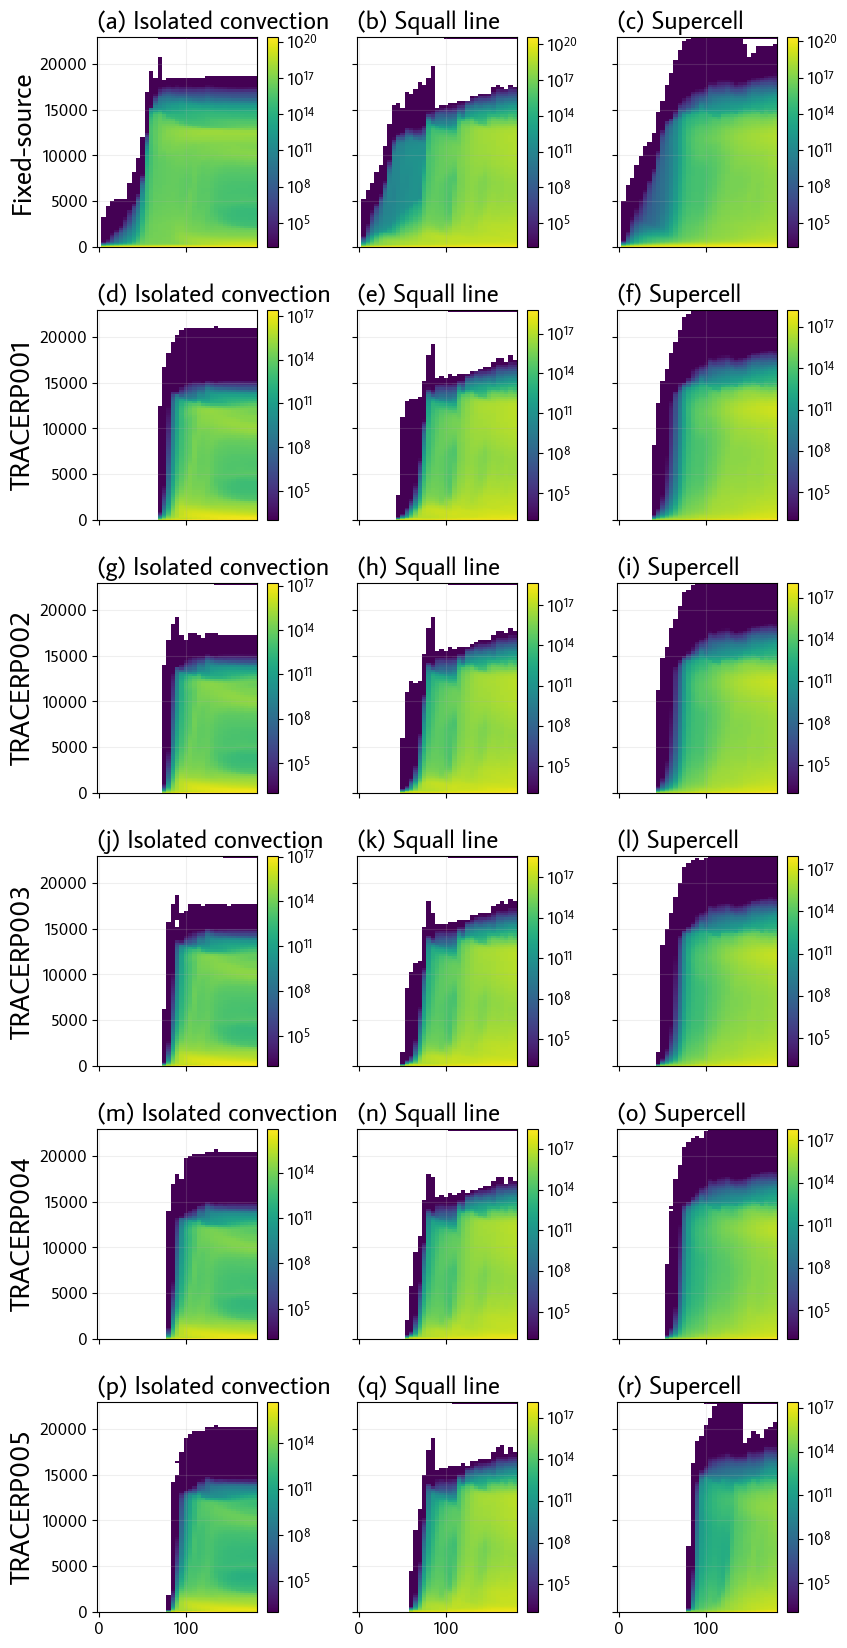

In [ ]:
cm.plotting.start_figure("tracer_height_heatmap")

fig, axs = plt.subplots(ncols=3, nrows=6, figsize=(8, 18), sharex=True, sharey=True)

for storm_ix, (storm, profile_ds) in enumerate(
    tqdm(full_domain_tracer_profiles.items())
):
    ax = axs[0, storm_ix]
    pc = axs[0, storm_ix].pcolormesh(
        profile_ds["t_minutes"].values,
        profile_ds["z"].values,
        profile_ds["total_fs_tracer_nc"].values.T,
        norm=colors.LogNorm(vmin=1000),
    )
    plt.colorbar(pc, ax=ax)
    ax.set_title(blt.axes_title(storm_ix, blt.STORM_LABELS[storm]))
    if storm_ix == 0:
        cm.plotting.add_row_header(ax, "Fixed-source")

    for tracer_ix, tracer in enumerate(blt.RS_TRACERS):
        ax = axs[tracer_ix + 1, storm_ix]
        pc = ax.pcolormesh(
            profile_ds["t_minutes"].values,
            profile_ds["z"].values,
            profile_ds[tracer + "_nc"].values.T,
            norm=colors.LogNorm(vmin=1000),
        )
        plt.colorbar(pc, ax=ax)
        ax.set_title(
            blt.axes_title(storm_ix + (3 * (tracer_ix + 1)), blt.STORM_LABELS[storm])
        )
        if storm_ix == 0:
            cm.plotting.add_row_header(ax, tracer)